In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def run_aero_lab(fan_speed, attack_angle, duration):
    dt = 0.02
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    # 3 Different Paper Airfoil Profiles & Parameters
    profiles = {
        "1. Flat Paper Plate": {
            "Cl_slope": 0.08, "Cd0": 0.15, "damping": 0.4, "vortex_strength": 1.8, "color": "#e74c3c"
        },
        "2. Symmetric Airfoil (NACA 0012)": {
            "Cl_slope": 0.10, "Cd0": 0.04, "damping": 1.5, "vortex_strength": 0.7, "color": "#f39c12"
        },
        "3. Cambered Airfoil (NACA 2412)": {
            "Cl_slope": 0.12, "Cd0": 0.02, "damping": 2.8, "vortex_strength": 0.2, "color": "#27ae60"
        }
    }

    rho = 1.225      # Air density (kg/m^3)
    S = 0.02         # Wing area (m^2)
    mass = 0.005     # Paper mass (5 grams)
    g = 9.81         # Gravity

    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(3, 3, height_ratios=[1.1, 1, 1])

    # --- TOP ROW: Flow Lines & Wake Vortices for Each Profile ---
    x_grid = np.linspace(-2, 4, 100)
    y_grid = np.linspace(-1.5, 1.5, 100)
    X, Y = np.meshgrid(x_grid, y_grid)

    for idx, (name, p) in enumerate(profiles.items()):
        ax_flow = fig.add_subplot(gs[0, idx])

        U = np.ones_like(X) * fan_speed
        wake_zone = (X > 0.5) & (np.abs(Y) < 0.6)

        V = np.zeros_like(Y)
        V[wake_zone] = p["vortex_strength"] * np.sin(4 * X[wake_zone]) * np.exp(-0.4 * X[wake_zone])
        U[wake_zone] -= p["vortex_strength"] * 0.3 * fan_speed * np.exp(-0.5 * X[wake_zone])

        ax_flow.streamplot(X, Y, U, V, color=p["color"], linewidth=1.2, density=1.3, arrowsize=1)

        chord = np.linspace(-0.5, 0.5, 50)
        if idx == 0:
            ax_flow.plot(chord, np.zeros_like(chord), color='black', linewidth=4)
        elif idx == 1:
            thick = 0.15 * (0.2969*np.sqrt(chord+0.5) - 0.126*(chord+0.5) - 0.3516*(chord+0.5)**2)
            ax_flow.fill_between(chord, -thick, thick, color='black')
        else:
            camber = 0.08 * (1 - (2*chord)**2)
            thick = 0.12 * (0.2969*np.sqrt(chord+0.5) - 0.126*(chord+0.5) - 0.3516*(chord+0.5)**2)
            ax_flow.fill_between(chord, camber - thick, camber + thick, color='black')

        ax_flow.set_title(f"{name}\n(Vortex Intensity: {p['vortex_strength']})", fontweight='bold', fontsize=10)
        ax_flow.set_xlim(-1.5, 3.5)
        ax_flow.set_ylim(-1.2, 1.2)
        ax_flow.set_yticks([])
        ax_flow.set_xlabel("Flow Direction ->")

    # --- MIDDLE GRAPH: Trajectory (Which one travels furthest?) ---
    ax_traj = fig.add_subplot(gs[1, :])

    # --- BOTTOM GRAPH: Stability (Which one stays stable over time?) ---
    ax_stab = fig.add_subplot(gs[2, :])

    results_summary = []

    for name, p in profiles.items():
        x = np.zeros(n_steps)
        y = np.ones(n_steps) * 1.5  # Dropped from 1.5m height
        vx = np.ones(n_steps) * (fan_speed * 0.4)
        vy = np.zeros(n_steps)
        theta = np.zeros(n_steps)

        for i in range(1, n_steps):
            if y[i-1] <= 0:
                x[i:] = x[i-1]
                y[i:] = 0
                theta[i:] = theta[i-1]
                break

            turbulence = p["vortex_strength"] * 2.5 * np.sin(8 * t[i]) * np.exp(-p["damping"] * 0.3 * t[i])
            theta[i] = attack_angle + turbulence

            alpha_rad = np.radians(theta[i])
            Cl = p["Cl_slope"] * theta[i] + (0.3 if "Cambered" in name else 0.0)
            Cd = p["Cd0"] + 0.05 * (Cl**2)

            v_rel = np.sqrt((fan_speed - vx[i-1])**2 + vy[i-1]**2) + vx[i-1]
            q = 0.5 * rho * (v_rel**2) * S

            L = q * Cl
            D = q * Cd

            ax = (L * np.sin(alpha_rad) - D * np.cos(alpha_rad) + 0.5*rho*(fan_speed**2)*S*0.05) / mass
            ay = (L * np.cos(alpha_rad) - D * np.sin(alpha_rad) - mass * g) / mass

            vx[i] = max(0.5, vx[i-1] + ax * dt)
            vy[i] = vy[i-1] + ay * dt
            x[i] = x[i-1] + vx[i] * dt
            y[i] = max(0, y[i-1] + vy[i] * dt)

        ax_traj.plot(x, y, label=f"{name} (Total Distance: {x[-1]:.2f} m)", color=p["color"], linewidth=2.5)
        ax_stab.plot(t, theta, label=f"{name} (Oscillation)", color=p["color"], linewidth=2)
        results_summary.append((name, x[-1], np.std(theta)))

    ax_traj.set_title("1. TEST: Which Design Travels Furthest? (Height vs. Distance Trajectory)", fontweight='bold', fontsize=12)
    ax_traj.set_xlabel("Horizontal Distance (meters)")
    ax_traj.set_ylabel("Height (meters)")
    ax_traj.axhline(0, color='black', linewidth=1.5)
    ax_traj.grid(True, linestyle='--', alpha=0.6)
    ax_traj.legend(loc="upper right")

    ax_stab.set_title("2. TEST: Which Design Stays Stable? (Time-dependent Pitch Oscillation)", fontweight='bold', fontsize=12)
    ax_stab.set_xlabel("Time (seconds)")
    ax_stab.set_ylabel("Wing Angle / Pitch Deviation (degrees)")
    ax_stab.axhline(attack_angle, color='gray', linestyle=':', label="Target Equilibrium Angle")
    ax_stab.grid(True, linestyle='--', alpha=0.6)
    ax_stab.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

    # Automated Result Summary
    furthest = max(results_summary, key=lambda item: item[1])
    most_stable = min(results_summary, key=lambda item: item[2])
    print(f"🏆 FURTHEST TRAVELING DESIGN: {furthest[0]} ({furthest[1]:.2f} meters)")
    print(f"⚖️ MOST STABLE DESIGN: {most_stable[0]} (Oscillation Deviation: ±{most_stable[2]:.2f}°)")

# --- INTERACTIVE CONTROL PANEL (ENGLISH) ---
style = {'description_width': 'initial'}
s_fan = widgets.FloatSlider(value=8.0, min=3.0, max=20.0, step=0.5, description='Fan Airflow Speed (m/s):', style=style)
s_angle = widgets.FloatSlider(value=6.0, min=0.0, max=15.0, step=1.0, description='Initial Attack Angle (°):', style=style)
s_time = widgets.FloatSlider(value=4.0, min=2.0, max=10.0, step=0.5, description='Simulation Duration (s):', style=style)

ui = widgets.VBox([
    widgets.HTML("<h3>🌬️ Paper Airfoil Wind Tunnel & Stability Simulator</h3>"),
    widgets.HBox([s_fan, s_angle, s_time])
])

out = widgets.interactive_output(run_aero_lab, {'fan_speed': s_fan, 'attack_angle': s_angle, 'duration': s_time})
display(ui, out)

Output()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def run_simulation(b):
    with out:
        clear_output(wait=True)

        # Arayüzden gelen değerleri al
        fan_speed = s_fan.value
        attack_angle = s_angle.value
        duration = s_time.value
        mass = s_mass.value

        dt = 0.02
        t = np.arange(0, duration, dt)
        n_steps = len(t)

        profiles = {
            "1. Flat Paper Plate": {
                "Cl_slope": 0.08, "Cd0": 0.15, "damping": 0.4, "vortex_strength": 1.8, "color": "#e74c3c"
            },
            "2. Symmetric Airfoil (NACA 0012)": {
                "Cl_slope": 0.10, "Cd0": 0.04, "damping": 1.5, "vortex_strength": 0.7, "color": "#f39c12"
            },
            "3. Cambered Airfoil (NACA 2412)": {
                "Cl_slope": 0.12, "Cd0": 0.02, "damping": 2.8, "vortex_strength": 0.2, "color": "#27ae60"
            }
        }

        rho = 1.225
        S = 0.02
        g = 9.81

        fig = plt.figure(figsize=(14, 11))
        gs = fig.add_gridspec(3, 3, height_ratios=[1.1, 1, 1])

        # --- FLOW LINES ---
        x_grid = np.linspace(-2, 4, 80)
        y_grid = np.linspace(-1.5, 1.5, 80)
        X, Y = np.meshgrid(x_grid, y_grid)

        for idx, (name, p) in enumerate(profiles.items()):
            ax_flow = fig.add_subplot(gs[0, idx])
            U = np.ones_like(X) * fan_speed
            wake_zone = (X > 0.5) & (np.abs(Y) < 0.6)

            V = np.zeros_like(Y)
            V[wake_zone] = p["vortex_strength"] * np.sin(4 * X[wake_zone]) * np.exp(-0.4 * X[wake_zone])
            U[wake_zone] -= p["vortex_strength"] * 0.2 * fan_speed * np.exp(-0.5 * X[wake_zone])

            ax_flow.streamplot(X, Y, U, V, color=p["color"], linewidth=1.2, density=1.2, arrowsize=1)

            chord = np.linspace(-0.5, 0.5, 50)
            if idx == 0:
                ax_flow.plot(chord, np.zeros_like(chord), color='black', linewidth=4)
            elif idx == 1:
                thick = 0.15 * (0.2969*np.sqrt(chord+0.5) - 0.126*(chord+0.5) - 0.3516*(chord+0.5)**2)
                ax_flow.fill_between(chord, -thick, thick, color='black')
            else:
                camber = 0.08 * (1 - (2*chord)**2)
                thick = 0.12 * (0.2969*np.sqrt(chord+0.5) - 0.126*(chord+0.5) - 0.3516*(chord+0.5)**2)
                ax_flow.fill_between(chord, camber - thick, camber + thick, color='black')

            ax_flow.set_title(f"{name}", fontweight='bold', fontsize=10)
            ax_flow.set_xlim(-1.5, 3.5)
            ax_flow.set_ylim(-1.2, 1.2)
            ax_flow.set_yticks([])
            ax_flow.set_xlabel("Flow Direction ->")

        ax_traj = fig.add_subplot(gs[1, :])
        ax_stab = fig.add_subplot(gs[2, :])

        results_summary = []

        for name, p in profiles.items():
            x = np.zeros(n_steps)
            y = np.ones(n_steps) * 1.5
            vx = np.zeros(n_steps)
            vy = np.zeros(n_steps)
            theta = np.zeros(n_steps)

            for i in range(1, n_steps):
                if y[i-1] <= 0:
                    x[i:] = x[i-1]
                    y[i:] = 0
                    theta[i:] = theta[i-1]
                    break

                turbulence = p["vortex_strength"] * 1.5 * np.sin(6 * t[i]) * np.exp(-p["damping"] * 0.4 * t[i])
                theta[i] = attack_angle + turbulence

                alpha_rad = np.radians(theta[i])
                Cl = p["Cl_slope"] * theta[i] + (0.2 if "Cambered" in name else 0.0)
                Cd = p["Cd0"] + 0.04 * (Cl**2)

                # Kararlı aerodinamik kuvvet hesap adımı (Ölçek düzeltildi)
                v_rel = fan_speed + vx[i-1]
                q = 0.5 * rho * (v_rel**2) * S

                L = q * Cl
                D = q * Cd

                ax = (0.5 * rho * (fan_speed**2) * S * 0.3 - D) / mass
                ay = (L - mass * g) / mass

                vx[i] = max(0.0, vx[i-1] + ax * dt)
                vy[i] = vy[i-1] + ay * dt
                x[i] = x[i-1] + vx[i] * dt
                y[i] = max(0, y[i-1] + vy[i] * dt)

            ax_traj.plot(x, y, label=f"{name} (Distance: {x[-1]:.2f} m)", color=p["color"], linewidth=2.5)
            ax_stab.plot(t, theta, label=f"{name} (Pitch)", color=p["color"], linewidth=2)
            results_summary.append((name, x[-1], np.std(theta)))

        ax_traj.set_title("1. TEST: Which Design Travels Furthest? (Trajectory)", fontweight='bold', fontsize=12)
        ax_traj.set_xlabel("Horizontal Distance (meters)")
        ax_traj.set_ylabel("Height (meters)")
        ax_traj.axhline(0, color='black', linewidth=1.5)
        ax_traj.grid(True, linestyle='--', alpha=0.6)
        ax_traj.legend(loc="upper right")

        ax_stab.set_title("2. TEST: Which Design Stays Stable? (Pitch Oscillation)", fontweight='bold', fontsize=12)
        ax_stab.set_xlabel("Time (seconds)")
        ax_stab.set_ylabel("Pitch Angle (degrees)")
        ax_stab.axhline(attack_angle, color='gray', linestyle=':', label="Target Angle")
        ax_stab.grid(True, linestyle='--', alpha=0.6)
        ax_stab.legend(loc="upper right")

        plt.tight_layout()
        plt.show()

        furthest = max(results_summary, key=lambda item: item[1])
        most_stable = min(results_summary, key=lambda item: item[2])
        print(f"🏆 FURTHEST TRAVELING DESIGN: {furthest[0]} ({furthest[1]:.2f} meters)")
        print(f"⚖️ MOST STABLE DESIGN: {most_stable[0]} (Oscillation Deviation: ±{most_stable[2]:.2f}°)")

# --- MATLAB TARZI ARAYÜZ VE RUN BUTONU ---
style = {'description_width': 'initial'}

s_fan = widgets.FloatSlider(value=8.0, min=2.0, max=25.0, step=0.5, description='Fan Speed (m/s):', style=style)
s_angle = widgets.FloatSlider(value=5.0, min=0.0, max=15.0, step=1.0, description='Attack Angle (°):', style=style)
s_mass = widgets.FloatSlider(value=0.005, min=0.001, max=0.02, step=0.001, description='Paper Mass (kg):', style=style)
s_time = widgets.FloatSlider(value=4.0, min=2.0, max=8.0, step=0.5, description='Duration (s):', style=style)

# MATLAB'deki "RUN" butonunu temsil eder
run_button = widgets.Button(
    description='▶ RUN SIMULATION',
    disabled=False,
    button_style='success', # Yeşil renkli şık buton
    tool_tip='Click to run simulation with current parameters',
    icon='play'
)

run_button.on_click(run_simulation)

# Arayüz Yerleşimi (Layout)
ui = widgets.VBox([
    widgets.HTML("<h3 style='color: #2c3e50;'>🎛️ MATLAB-Style Aerodynamics Control Panel</h3>"),
    widgets.HBox([s_fan, s_angle]),
    widgets.HBox([s_mass, s_time]),
    run_button,
    widgets.HTML("<hr>")
])

out = widgets.Output()

display(ui, out)

Output()

In [3]:
# Gerekli kütüphaneleri yükle (Colab'de zaten vardır ama garanti olsun)
!pip install -q flask flask-cors numpy

from flask import Flask, render_template_string, request, jsonify
from flask_cors import CORS
import numpy as np

app = Flask(__name__)
CORS(app)

# Tek Sayfalık Modern HTML/CSS/JS Arayüzü (Gönderdiğin NASA Paneli Temasında)
HTML_PAGE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Paper Airfoil Aerodynamics & Stability Lab</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { background-color: #0d1117; color: #c9d1d9; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; margin: 0; padding: 20px; }
        .header { background: #161b22; padding: 20px; border-radius: 12px; border: 1px solid #30363d; margin-bottom: 20px; box-shadow: 0 4px 12px rgba(0,0,0,0.3); }
        .header h1 { margin: 0; font-size: 22px; color: #58a6ff; }
        .header p { margin: 5px 0 0 0; color: #8b949e; font-size: 13px; }

        .panel { background: #161b22; padding: 20px; border-radius: 12px; border: 1px solid #30363d; margin-bottom: 20px; }
        .panel-title { font-size: 14px; font-weight: bold; color: #8b949e; margin-bottom: 15px; text-transform: uppercase; letter-spacing: 1px; }

        .inputs-grid { display: grid; grid-template-columns: repeat(auto-fit, minmax(200px, 1fr)); gap: 15px; margin-bottom: 20px; }
        .input-card { background: #0d1117; border: 1px solid #30363d; padding: 15px; border-radius: 8px; }
        .input-card label { display: block; font-size: 12px; color: #8b949e; margin-bottom: 8px; font-weight: bold; }
        .input-card input, .input-card select { width: 100%; background: #161b22; border: 1px solid #30363d; color: #fff; padding: 8px; border-radius: 6px; font-size: 14px; }

        .btn-analyze { background: linear-gradient(135deg, #238636, #2ea043); color: white; border: none; padding: 12px 25px; font-size: 15px; font-weight: bold; border-radius: 8px; cursor: pointer; width: 100%; transition: 0.2s; box-shadow: 0 4px 10px rgba(35,134,54,0.4); }
        .btn-analyze:hover { opacity: 0.9; }

        .results-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
        @media(max-width: 900px) { .results-grid { grid-template-columns: 1fr; } }

        .chart-card { background: #161b22; border: 1px solid #30363d; padding: 15px; border-radius: 12px; }
        .chart-card h3 { font-size: 15px; color: #58a6ff; margin-top: 0; }

        .summary-box { background: #0d1117; border-left: 4px solid #2ea043; padding: 15px; border-radius: 6px; margin-top: 20px; font-size: 14px; }
    </style>
</head>
<body>

    <div class="header">
        <h1>🌬️ Paper Airfoil Aerodynamics & Stability Lab</h1>
        <p>Interactive Real-Time Wind Tunnel Simulation & Time-Dependent Trajectory Analysis</p>
    </div>

    <div class="panel">
        <div class="panel-title">Giriş Parametreleri / Control Parameters</div>
        <div class="inputs-grid">
            <div class="input-card">
                <label>Fan Airflow Speed (m/s)</label>
                <input type="number" id="fan_speed" value="8.0" step="0.5" min="2" max="25">
            </div>
            <div class="input-card">
                <label>Initial Attack Angle (°)</label>
                <input type="number" id="attack_angle" value="6.0" step="1" min="0" max="20">
            </div>
            <div class="input-card">
                <label>Paper Mass (kg)</label>
                <input type="number" id="mass" value="0.005" step="0.001" min="0.001" max="0.02">
            </div>
            <div class="input-card">
                <label>Simulation Duration (s)</label>
                <input type="number" id="duration" value="4.0" step="0.5" min="1" max="10">
            </div>
        </div>
        <button class="btn-analyze" onclick="runSimulation()">⚡ Analizi Başlat / Run Simulation</button>
    </div>

    <div class="results-grid">
        <div class="chart-card">
            <h3>1. Trajectory Analysis (Distance vs. Height)</h3>
            <canvas id="trajChart"></canvas>
        </div>
        <div class="chart-card">
            <h3>2. Stability Analysis (Pitch Oscillation over Time)</h3>
            <canvas id="stabChart"></canvas>
        </div>
    </div>

    <div class="summary-box" id="summaryText">
        <b>Status:</b> Waiting for user input. Click "Run Simulation" to calculate aerodynamics.
    </div>

<script>
    let trajChartInstance = null;
    let stabChartInstance = null;

    async function runSimulation() {
        const fan_speed = parseFloat(document.getElementById('fan_speed').value);
        const attack_angle = parseFloat(document.getElementById('attack_angle').value);
        const mass = parseFloat(document.getElementById('mass').value);
        const duration = parseFloat(document.getElementById('duration').value);

        const response = await fetch('/simulate', {
            method: 'POST',
            headers: { 'Content-Type': 'application/json' },
            body: JSON.stringify({ fan_speed, attack_angle, mass, duration })
        });

        const data = await response.json();
        renderCharts(data);
    }

    function renderCharts(data) {
        // Trajectory Chart
        const ctxTraj = document.getElementById('trajChart').getContext('2d');
        if (trajChartInstance) trajChartInstance.destroy();

        trajChartInstance = new Chart(ctxTraj, {
            type: 'line',
            data: {
                datasets: data.trajectories.map(traj => ({
                    label: traj.name + ` (Dist: ${traj.total_dist}m)`,
                    data: traj.points,
                    borderColor: traj.color,
                    borderWidth: 2.5,
                    pointRadius: 0,
                    fill: false
                }))
            },
            options: {
                responsive: true,
                scales: {
                    x: { type: 'linear', title: { display: true, text: 'Horizontal Distance (m)', color: '#8b949e' }, grid: { color: '#30363d' } },
                    y: { title: { display: true, text: 'Height (m)', color: '#8b949e' }, grid: { color: '#30363d' } }
                }
            }
        });

        // Stability Chart
        const ctxStab = document.getElementById('stabChart').getContext('2d');
        if (stabChartInstance) stabChartInstance.destroy();

        stabChartInstance = new Chart(ctxStab, {
            type: 'line',
            data: {
                labels: data.time,
                datasets: data.stabilities.map(stab => ({
                    label: stab.name,
                    data: stab.values,
                    borderColor: stab.color,
                    borderWidth: 2,
                    pointRadius: 0,
                    fill: false
                }))
            },
            options: {
                responsive: true,
                scales: {
                    x: { title: { display: true, text: 'Time (s)', color: '#8b949e' }, grid: { color: '#30363d' } },
                    y: { title: { display: true, text: 'Pitch Angle (deg)', color: '#8b949e' }, grid: { color: '#30363d' } }
                }
            }
        });

        document.getElementById('summaryTextinnerHTML = `🏆 <b>Furthest Design:</b> ${data.furthest} | ⚖️ <b>Most Stable Design:</b> ${data.stable}`;
    }

    // Sayfa açıldığında otomatik ilk analizi çalıştır
    window.onload = runSimulation;
</script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_PAGE)

@app.route('/simulate', methods=['POST'])
def simulate():
    req = request.json
    fan_speed = req.get('fan_speed', 8.0)
    attack_angle = req.get('attack_angle', 6.0)
    mass = req.get('mass', 0.005)
    duration = req.get('duration', 4.0)

    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    profiles = {
        "1. Flat Paper Plate": {"Cl_slope": 0.08, "Cd0": 0.15, "damping": 0.4, "color": "#e74c3c"},
        "2. Symmetric Airfoil": {"Cl_slope": 0.10, "Cd0": 0.04, "damping": 1.5, "color": "#f39c12"},
        "3. Cambered Airfoil": {"Cl_slope": 0.12, "Cd0": 0.02, "damping": 2.8, "color": "#27ae60"}
    }

    rho, S, g = 1.225, 0.02, 9.81
    trajectories, stabilities = [], []
    results_summary = []

    for name, p in profiles.items():
        x = np.zeros(n_steps)
        y = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        theta = np.zeros(n_steps)

        points = []
        vals = []

        for i in range(1, n_steps):
            if y[i-1] <= 0:
                x[i:] = x[i-1]
                y[i:] = 0
                theta[i:] = theta[i-1]
                break

            turbulence = 1.2 * np.sin(5 * t[i]) * np.exp(-p["damping"] * 0.4 * t[i])
            theta[i] = attack_angle + turbulence

            Cl = p["Cl_slope"] * theta[i] + (0.2 if "Cambered" in name else 0.0)
            Cd = p["Cd0"] + 0.04 * (Cl**2)

            v_rel = fan_speed + vx
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd

            ax = (0.5 * rho * (fan_speed**2) * S * 0.3 - D) / mass
            ay = (L - mass * g) / mass

            vx = max(0.0, vx + ax * dt)
            vy = vy + ay * dt
            x[i] = x[i-1] + vx * dt
            y[i] = max(0, y[i-1] + vy * dt)

            points.append({'x': round(float(x[i]), 2), 'y': round(float(y[i]), 2)})
            vals.append(round(float(theta[i]), 2))

        total_dist = round(float(x[-1]), 2)
        stability_dev = round(float(np.std(theta)), 2)
        results_summary.append((name, total_dist, stability_dev))

        trajectories.append({"name": name, "total_dist": total_dist, "color": p["color"], "points": points})
        stabilities.append({"name": name, "color": p["color"], "values": vals})

    furthest = max(results_summary, key=lambda item: item[1])[0]
    stable = min(results_summary, key=lambda item: item[2])[0]

    return jsonify({
        "time": [round(float(val), 2) for val in t],
        "trajectories": trajectories,
        "stabilities": stabilities,
        "furthest": furthest,
        "stable": stable
    })

if __name__ == '__main__':
    print("🚀 Web sunucusu başlatılıyor...")
    app.run(port=5000)

🚀 Web sunucusu başlatılıyor...
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def run_notebook_app(b=None):
    with out_output:
        clear_output(wait=True)

        # Arayüzdeki kutulardan güncel değerleri al
        fan_speed = in_fan.value
        attack_angle = in_angle.value
        mass = in_mass.value
        duration = in_duration.value

        dt = 0.05
        t = np.arange(0, duration, dt)
        n_steps = len(t)

        profiles = {
            "1. Flat Paper Plate": {"Cl_slope": 0.08, "Cd0": 0.15, "damping": 0.4, "color": "#e74c3c"},
            "2. Symmetric Airfoil": {"Cl_slope": 0.10, "Cd0": 0.04, "damping": 1.5, "color": "#f39c12"},
            "3. Cambered Airfoil": {"Cl_slope": 0.12, "Cd0": 0.02, "damping": 2.8, "color": "#27ae60"}
        }

        rho, S, g = 1.225, 0.02, 9.81

        fig = plt.figure(figsize=(12, 10))
        gs = fig.add_gridspec(2, 1, height_ratios=[1, 1])

        ax_traj = fig.add_subplot(gs[0])
        ax_stab = fig.add_subplot(gs[1])

        results_summary = []

        for name, p in profiles.items():
            x = np.zeros(n_steps)
            y = np.ones(n_steps) * 1.5
            vx, vy = 0.0, 0.0
            theta = np.zeros(n_steps)

            for i in range(1, n_steps):
                if y[i-1] <= 0:
                    x[i:] = x[i-1]
                    y[i:] = 0
                    theta[i:] = theta[i-1]
                    break

                turbulence = 1.2 * np.sin(5 * t[i]) * np.exp(-p["damping"] * 0.4 * t[i])
                theta[i] = attack_angle + turbulence

                Cl = p["Cl_slope"] * theta[i] + (0.2 if "Cambered" in name else 0.0)
                Cd = p["Cd0"] + 0.04 * (Cl**2)

                v_rel = fan_speed + vx
                q = 0.5 * rho * (v_rel**2) * S
                L, D = q * Cl, q * Cd

                ax = (0.5 * rho * (fan_speed**2) * S * 0.3 - D) / mass
                ay = (L - mass * g) / mass

                vx = max(0.0, vx + ax * dt)
                vy = vy + ay * dt
                x[i] = x[i-1] + vx * dt
                y[i] = max(0, y[i-1] + vy * dt)

            total_dist = x[-1]
            stability_dev = np.std(theta)
            results_summary.append((name, total_dist, stability_dev))

            ax_traj.plot(x, y, label=f"{name} (Dist: {total_dist:.2f}m)", color=p["color"], linewidth=2.5)
            ax_stab.plot(t, theta, label=f"{name}", color=p["color"], linewidth=2)

        # Grafik 1: Trajectory
        ax_traj.set_title("1. TRAJECTORY ANALYSIS (Horizontal Distance vs. Height)", fontsize=11, fontweight='bold', color='#2c3e50')
        ax_traj.set_xlabel("Horizontal Distance (meters)")
        ax_traj.set_ylabel("Height (meters)")
        ax_traj.axhline(0, color='black', linewidth=1.2)
        ax_traj.grid(True, linestyle='--', alpha=0.5)
        ax_traj.legend(loc="upper right")

        # Grafik 2: Stability
        ax_stab.set_title("2. STABILITY ANALYSIS (Pitch Oscillation over Time)", fontsize=11, fontweight='bold', color='#2c3e50')
        ax_stab.set_xlabel("Time (seconds)")
        ax_stab.set_ylabel("Pitch Angle (degrees)")
        ax_stab.axhline(attack_angle, color='gray', linestyle=':', label="Target Equilibrium Angle")
        ax_stab.grid(True, linestyle='--', alpha=0.5)
        ax_stab.legend(loc="upper right")

        plt.tight_layout()
        plt.show()

        furthest = max(results_summary, key=lambda item: item[1])
        most_stable = min(results_summary, key=lambda item: item[2])
        print(f"🏆 FURTHEST TRAVELING DESIGN: {furthest[0]} ({furthest[1]:.2f} meters)")
        print(f"⚖️ MOST STABLE DESIGN: {most_stable[0]} (Oscillation Deviation: ±{most_stable[2]:.2f}°)")

# --- KONTROL PANELİ WIDGET'LARI ---
style = {'description_width': 'initial'}

in_fan = widgets.FloatTextBox(value=8.0, description='Fan Speed (m/s):', style=style)
in_angle = widgets.FloatTextBox(value=6.0, description='Attack Angle (°):', style=style)
in_mass = widgets.FloatTextBox(value=0.005, description='Paper Mass (kg):', style=style)
in_duration = widgets.FloatTextBox(value=4.0, description='Duration (s):', style=style)

btn_run = widgets.Button(
    description='▶ RUN SIMULATION',
    button_style='success',
    tooltip='Click to calculate and update charts'
)

btn_run.on_click(run_notebook_app)

# Arayüz Düzeni
controls = widgets.VBox([
    widgets.HTML("<h3 style='margin-bottom:10px;'>🎛️ Paper Airfoil Control Panel</h3>"),
    widgets.HBox([in_fan, in_angle]),
    widgets.HBox([in_mass, in_duration]),
    widgets.HTML("<br>"),
    btn_run,
    widgets.HTML("<hr style='margin:15px 0;'>")
])

out_output = widgets.Output()

# Başlangıçta paneli ve çıktıyı göster
display(controls, out_output)

# İlk çalıştırmayı otomatik tetikle
run_notebook_app()

AttributeError: module 'ipywidgets' has no attribute 'FloatTextBox'

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def run_notebook_app(b=None):
    with out_output:
        clear_output(wait=True)

        # Kutulardan güncel değerleri al
        fan_speed = in_fan.value
        attack_angle = in_angle.value
        mass = in_mass.value
        duration = in_duration.value

        dt = 0.05
        t = np.arange(0, duration, dt)
        n_steps = len(t)

        profiles = {
            "1. Flat Paper Plate": {"Cl_slope": 0.08, "Cd0": 0.15, "damping": 0.4, "color": "#e74c3c"},
            "2. Symmetric Airfoil": {"Cl_slope": 0.10, "Cd0": 0.04, "damping": 1.5, "color": "#f39c12"},
            "3. Cambered Airfoil": {"Cl_slope": 0.12, "Cd0": 0.02, "damping": 2.8, "color": "#27ae60"}
        }

        rho, S, g = 1.225, 0.02, 9.81

        fig = plt.figure(figsize=(12, 10))
        gs = fig.add_gridspec(2, 1, height_ratios=[1, 1])

        ax_traj = fig.add_subplot(gs[0])
        ax_stab = fig.add_subplot(gs[1])

        results_summary = []

        for name, p in profiles.items():
            x = np.zeros(n_steps)
            y = np.ones(n_steps) * 1.5
            vx, vy = 0.0, 0.0
            theta = np.zeros(n_steps)

            for i in range(1, n_steps):
                if y[i-1] <= 0:
                    x[i:] = x[i-1]
                    y[i:] = 0
                    theta[i:] = theta[i-1]
                    break

                turbulence = 1.2 * np.sin(5 * t[i]) * np.exp(-p["damping"] * 0.4 * t[i])
                theta[i] = attack_angle + turbulence

                Cl = p["Cl_slope"] * theta[i] + (0.2 if "Cambered" in name else 0.0)
                Cd = p["Cd0"] + 0.04 * (Cl**2)

                v_rel = fan_speed + vx
                q = 0.5 * rho * (v_rel**2) * S
                L, D = q * Cl, q * Cd

                ax = (0.5 * rho * (fan_speed**2) * S * 0.3 - D) / mass
                ay = (L - mass * g) / mass

                vx = max(0.0, vx + ax * dt)
                vy = vy + ay * dt
                x[i] = x[i-1] + vx * dt
                y[i] = max(0, y[i-1] + vy * dt)

            total_dist = x[-1]
            stability_dev = np.std(theta)
            results_summary.append((name, total_dist, stability_dev))

            ax_traj.plot(x, y, label=f"{name} (Dist: {total_dist:.2f}m)", color=p["color"], linewidth=2.5)
            ax_stab.plot(t, theta, label=f"{name}", color=p["color"], linewidth=2)

        # Grafik 1: Trajectory
        ax_traj.set_title("1. TRAJECTORY ANALYSIS (Horizontal Distance vs. Height)", fontsize=11, fontweight='bold', color='#2c3e50')
        ax_traj.set_xlabel("Horizontal Distance (meters)")
        ax_traj.set_ylabel("Height (meters)")
        ax_traj.axhline(0, color='black', linewidth=1.2)
        ax_traj.grid(True, linestyle='--', alpha=0.5)
        ax_traj.legend(loc="upper right")

        # Grafik 2: Stability
        ax_stab.set_title("2. STABILITY ANALYSIS (Pitch Oscillation over Time)", fontsize=11, fontweight='bold', color='#2c3e50')
        ax_stab.set_xlabel("Time (seconds)")
        ax_stab.set_ylabel("Pitch Angle (degrees)")
        ax_stab.axhline(attack_angle, color='gray', linestyle=':', label="Target Equilibrium Angle")
        ax_stab.grid(True, linestyle='--', alpha=0.5)
        ax_stab.legend(loc="upper right")

        plt.tight_layout()
        plt.show()

        furthest = max(results_summary, key=lambda item: item[1])
        most_stable = min(results_summary, key=lambda item: item[2])
        print(f"🏆 FURTHEST TRAVELING DESIGN: {furthest[0]} ({furthest[1]:.2f} meters)")
        print(f"⚖️ MOST STABLE DESIGN: {most_stable[0]} (Oscillation Deviation: ±{most_stable[2]:.2f}°)")

# --- DOĞRU WIDGET SINIFI (BoundedFloatText) ---
style = {'description_width': 'initial'}

in_fan = widgets.BoundedFloatText(value=8.0, min=1.0, max=50.0, step=0.5, description='Fan Speed (m/s):', style=style)
in_angle = widgets.BoundedFloatText(value=6.0, min=0.0, max=45.0, step=1.0, description='Attack Angle (°):', style=style)
in_mass = widgets.BoundedFloatText(value=0.005, min=0.0001, max=0.1, step=0.001, description='Paper Mass (kg):', style=style)
in_duration = widgets.BoundedFloatText(value=4.0, min=1.0, max=20.0, step=0.5, description='Duration (s):', style=style)

btn_run = widgets.Button(
    description='▶ RUN SIMULATION',
    button_style='success',
    tooltip='Click to calculate and update charts'
)

btn_run.on_click(run_notebook_app)

controls = widgets.VBox([
    widgets.HTML("<h3 style='margin-bottom:10px;'>🎛️ Paper Airfoil Control Panel</h3>"),
    widgets.HBox([in_fan, in_angle]),
    widgets.HBox([in_mass, in_duration]),
    widgets.HTML("<br>"),
    btn_run,
    widgets.HTML("<hr style='margin:15px 0;'>")
])

out_output = widgets.Output()

display(controls, out_output)
run_notebook_app()

Output()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# --- GERÇEK KANAT PROFİLİ VERİTABANI (NACA / Tarihsel Profiller) ---
AIRFOIL_DB = {
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3}
}

def generate_airfoil_coords(camber, thickness, n_points=100):
    x = np.linspace(0, 1, n_points)
    # NACA kalınlık dağılımı formülü
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)

    # Kamber (eğrilik) çizgisi
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)

    xu, yu = x - 0.5, yc + yt
    xl, yl = x - 0.5, yc - yt
    return xu, yu, xl, yl, yc

def run_matlab_cfd(b=None):
    with out_area:
        clear_output(wait=True)

        # Arayüzden girilen sayısal değerleri al
        v_fan = in_speed.value          # m/s
        alpha_deg = in_angle.value      # derece
        mass = in_mass.value / 1000.0   # gram -> kg çevrimi
        duration = in_time.value        # saniye
        chord_len = in_chord.value / 100.0 # cm -> metre

        # Kullanıcı tarafından özelleştirilen ekstra çarpanlar
        custom_camber_mult = in_camber_mod.value / 100.0
        custom_thick_mult = in_thick_mod.value / 100.0

        selected_names = [dd_wing1.value, dd_wing2.value, dd_wing3.value]
        colors = ['#00d2d3', '#ff9f43', '#1dd1a1'] # Foil.tools / Modern MATLAB renkleri

        rho = 1.225     # Hava yoğunluğu (kg/m^3)
        span = 0.20     # Kanat açıklığı (20 cm standart kağıt)
        S = chord_len * span
        g = 9.81

        dt = 0.02
        t = np.arange(0, duration, dt)
        n_steps = len(t)

        # --- GRAFİK ALANI (MATLAB / FOIL.TOOLS DARK THEME) ---
        plt.style.use('dark_background')
        fig = plt.figure(figsize=(16, 12))
        gs = fig.add_gridspec(3, 3, height_ratios=[1.2, 1, 1], hspace=0.38, wspace=0.25)

        # 1. SATIR: 2D CFD AKIŞ ÇİZGİLERİ VE KANAT KESİTLERİ
        x_grid = np.linspace(-1.2, 2.2, 90)
        y_grid = np.linspace(-0.8, 0.8, 90)
        X, Y = np.meshgrid(x_grid, y_grid)

        summary_data = []

        # Alt grafik eksenlerini tanımla
        ax_dist = fig.add_subplot(gs[1, :2])
        ax_drag = fig.add_subplot(gs[1, 2])
        ax_stab = fig.add_subplot(gs[2, :])

        for idx, w_name in enumerate(selected_names):
            base = AIRFOIL_DB[w_name]
            color = colors[idx]

            # Efektif kamber ve kalınlık
            eff_camber = base["camber"] + custom_camber_mult
            eff_thick = max(0.01, base["thickness"] * custom_thick_mult)

            # --- 2D CFD STREAMPLOT (TEK RENK AKIŞ + GİRDAP) ---
            ax_cfd = fig.add_subplot(gs[0, idx])

            # Potansiyel akış + Arka iz bölgesi (Wake) girdap modeli
            alpha_rad = np.radians(alpha_deg)
            U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
            V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

            # Kanat etrafındaki saptırma (Circulation / Upwash-Downwash)
            R2 = X**2 + Y**2 + 0.08
            gamma = (eff_camber * 4.0 + alpha_rad * 1.5) * v_fan
            U += (gamma * Y) / (2 * np.pi * R2)
            V -= (gamma * X) / (2 * np.pi * R2)

            # Arka girdap (Vortex shedding) şiddeti: Kalınlık ve düşük sönümleme artırır
            vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)
            wake_mask = (X > 0.45) & (np.abs(Y) < 0.35)
            V[wake_mask] += vortex_intensity * np.sin(10 * X[wake_mask]) * np.exp(-1.2 * X[wake_mask])

            ax_cfd.streamplot(X, Y, U, V, color=color, linewidth=1.1, density=1.35, arrowsize=0.9)

            # Kanat profilini çiz (Foil.tools görünümü)
            xu, yu, xl, yl, yc = generate_airfoil_coords(eff_camber, eff_thick)
            # Hücum açısına göre profili döndür
            rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
            rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
            rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
            rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

            ax_cfd.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
                        np.concatenate([rot_y_u, rot_y_l[::-1]]),
                        color='#ffffff', zorder=5)

            ax_cfd.set_title(f"Wing {idx+1}: {w_name}\nThickness: {eff_thick*100:.1f}% | Camber: {eff_camber*100:.1f}%",
                             fontsize=10, fontweight='bold', color=color)
            ax_cfd.set_xlim(-1.0, 2.0)
            ax_cfd.set_ylim(-0.7, 0.7)
            ax_cfd.set_xlabel("X / Chord", fontsize=8)
            ax_cfd.set_ylabel("Y / Chord", fontsize=8)
            ax_cfd.grid(True, alpha=0.15)

            # --- ZAMANA BAĞLI FİZİK VE AERODİNAMİK ANALİZ ---
            x_pos = np.zeros(n_steps)
            y_pos = np.ones(n_steps) * 1.5 # 1.5m yükseklikten test
            vx, vy = 0.0, 0.0
            pitch_t = np.zeros(n_steps)
            drag_t = np.zeros(n_steps)
            lift_t = np.zeros(n_steps)

            for i in range(1, n_steps):
                # Kararlılık (Pitch Oscillation) Dinamiği
                # Zamanla rüzgara oturma (settling time) simülasyonu
                settling = np.exp(-base["damping"] * 0.8 * t[i])
                oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
                pitch_t[i] = alpha_deg + oscillation

                eff_alpha_rad = np.radians(pitch_t[i])
                # İnce Kanat Teorisi (Thin Airfoil Theory): Cl = 2 * pi * alpha + Cl0
                Cl = 2 * np.pi * eff_alpha_rad + (eff_camber * 10.0)
                Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

                v_rel = max(0.5, v_fan - vx * 0.3)
                q = 0.5 * rho * (v_rel**2) * S

                L = q * Cl
                D = q * Cd
                drag_t[i] = D
                lift_t[i] = L

                if y_pos[i-1] > 0:
                    ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                    ay_acc = (L - mass * g) / mass
                    vx = max(0.0, vx + ax_acc * dt)
                    vy = vy + ay_acc * dt
                    x_pos[i] = x_pos[i-1] + vx * dt
                    y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
                else:
                    x_pos[i] = x_pos[i-1]
                    y_pos[i] = 0.0

            # Grafikleri çiz
            ax_dist.plot(t, x_pos, label=f"{w_name} (Max: {x_pos[-1]:.2f} m)", color=color, linewidth=2.2)
            ax_stab.plot(t, pitch_t, label=f"{w_name} (Std Dev: ±{np.std(pitch_t):.2f}°)", color=color, linewidth=2.0)

            # Ortalama Direnç ve Kaldırma Verisi
            avg_drag = np.mean(drag_t[1:])
            avg_lift = np.mean(lift_t[1:])
            settling_time = 3.0 / (base["damping"] * 0.8) if base["damping"] > 0 else duration
            summary_data.append((w_name, x_pos[-1], np.std(pitch_t), avg_drag, avg_lift, min(duration, settling_time)))

        # Grafik 2A: Zamana Bağlı Alınan Mesafe
        ax_dist.set_title("TIME-DEPENDENT HORIZONTAL DISTANCE (Which Travels Furthest?)", fontsize=11, fontweight='bold')
        ax_dist.set_xlabel("Time (s)")
        ax_dist.set_ylabel("Distance Traveled (m)")
        ax_dist.grid(True, alpha=0.2)
        ax_dist.legend(loc="upper left")

        # Grafik 2B: Hava Direnci (Drag) ve Kaldırma (Lift) Karşılaştırması
        names_short = [s[0].split()[0] for s in summary_data]
        drags = [s[3] for s in summary_data]
        lifts = [s[4] for s in summary_data]
        x_bar = np.arange(len(names_short))
        ax_drag.bar(x_bar - 0.15, lifts, width=0.3, label="Lift Force (N)", color="#1dd1a1")
        ax_drag.bar(x_bar + 0.15, drags, width=0.3, label="Air Drag (N)", color="#ff6b6b")
        ax_drag.set_xticks(x_bar)
        ax_drag.set_xticklabels(names_short)
        ax_drag.set_title("AERODYNAMIC FORCES (N)", fontsize=11, fontweight='bold')
        ax_drag.set_ylabel("Force (Newton)")
        ax_drag.grid(True, alpha=0.2)
        ax_drag.legend()

        # Grafik 3: Zamana Bağlı Kararlılık (Pitch Angle Settling)
        ax_stab.set_title("TIME-DEPENDENT STABILITY & WIND SETTLING ANALYSIS (Pitch Angle vs. Time)", fontsize=11, fontweight='bold')
        ax_stab.set_xlabel("Time (s)")
        ax_stab.set_ylabel("Pitch Angle (°)")
        ax_stab.axhline(alpha_deg, color='white', linestyle='--', alpha=0.5, label=f"Target Attack Angle ({alpha_deg}°)")
        ax_stab.grid(True, alpha=0.2)
        ax_stab.legend(loc="upper right")

        plt.show()

        # --- MATLAB KOMUT PENCERESİ TARZI SAYISAL RAPOR ---
        print("="*85)
        print(f"{'AIRFOIL MODEL':<28} | {'DIST (m)':<9} | {'DRAG (N)':<9} | {'LIFT (N)':<9} | {'STABILITY (±°)':<14} | {'SETTLING (s)'}")
        print("-"*85)
        for row in summary_data:
            print(f"{row[0]:<28} | {row[1]:<9.2f} | {row[3]:<9.4f} | {row[4]:<9.4f} | ±{row[2]:<13.2f} | {row[5]:.2f} s")
        print("="*85)

        furthest = max(summary_data, key=lambda x: x[1])
        most_stable = min(summary_data, key=lambda x: x[2])
        lowest_drag = min(summary_data, key=lambda x: x[3])
        print(f"🏆 FURTHEST TRAVELING : {furthest[0]} ({furthest[1]:.2f} m)")
        print(f"⚖️ MOST STABLE WING   : {most_stable[0]} (Deviation: ±{most_stable[2]:.2f}° | Settled in ~{most_stable[5]:.1f}s)")
        print(f"💨 LOWEST AIR DRAG    : {lowest_drag[0]} ({lowest_drag[3]:.4f} N)")

# --- MATLAB APP DESIGNER TARZI SAYISAL GİRİŞ ARAYÜZÜ (SLIDER YOK) ---
style = {'description_width': '165px'}
layout_box = widgets.Layout(width='290px', margin='4px 10px 4px 0px')

# 3 Kanat Seçimi
dd_wing1 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="Flat Paper Plate (Control)", description="Wing 1 Profile:", style=style, layout=layout_box)
dd_wing2 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="NACA 0012 (Symmetric)", description="Wing 2 Profile:", style=style, layout=layout_box)
dd_wing3 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="NACA 2412 (Classic Cambered)", description="Wing 3 Profile:", style=style, layout=layout_box)

# Sayısal Giriş Kutuları (Birimli)
in_speed = widgets.BoundedFloatText(value=8.0, min=1.0, max=40.0, step=0.5, description="Fan Airflow Speed [m/s]:", style=style, layout=layout_box)
in_angle = widgets.BoundedFloatText(value=6.0, min=-5.0, max=25.0, step=0.5, description="Attack Angle [deg]:", style=style, layout=layout_box)
in_mass = widgets.BoundedFloatText(value=5.0, min=0.5, max=100.0, step=0.5, description="Paper Mass [gram]:", style=style, layout=layout_box)
in_chord = widgets.BoundedFloatText(value=10.0, min=2.0, max=50.0, step=1.0, description="Chord Length [cm]:", style=style, layout=layout_box)
in_time = widgets.BoundedFloatText(value=5.0, min=1.0, max=20.0, step=0.5, description="Simulation Time [s]:", style=style, layout=layout_box)

# Foil.tools Tarzı Geometri Modifikasyonları
in_camber_mod = widgets.BoundedFloatText(value=0.0, min=-5.0, max=10.0, step=0.5, description="Extra Camber [%]:", style=style, layout=layout_box)
in_thick_mod = widgets.BoundedFloatText(value=100.0, min=20.0, max=200.0, step=10.0, description="Thickness Scale [%]:", style=style, layout=layout_box)

btn_run = widgets.Button(
    description="▶ RUN CFD & STABILITY ANALYSIS",
    button_style="info",
    layout=widgets.Layout(width='900px', height='42px', margin='10px 0px')
)
btn_run.style.font_weight = 'bold'
btn_run.on_click(run_matlab_cfd)

# Panel Düzeni
panel_ui = widgets.VBox([
    widgets.HTML("<div style='background:#1e272e; color:#00d2d3; padding:12px; border-radius:6px; border-left:5px solid #00d2d3; font-family:monospace;'>"
                 "<h3 style='margin:0;'>MATLAB / FOIL.TOOLS — 2D AIRFOIL CFD & STABILITY WORKBENCH</h3>"
                 "<span style='color:#d2dae2; font-size:12px;'>Select 3 airfoils, enter physical test parameters with units, and press RUN.</span></div>"),
    widgets.HTML("<b style='color:#576574; font-family:monospace;'>1. AIRFOIL SELECTION (DATABASE)</b>"),
    widgets.HBox([dd_wing1, dd_wing2, dd_wing3]),
    widgets.HTML("<b style='color:#576574; font-family:monospace;'>2. WIND TUNNEL & GEOMETRY PARAMETERS (NUMERICAL INPUTS)</b>"),
    widgets.HBox([in_speed, in_angle, in_time]),
    widgets.HBox([in_mass, in_chord, in_camber_mod]),
    widgets.HBox([in_thick_mod]),
    btn_run
])

out_area = widgets.Output()
display(panel_ui, out_area)
run_matlab_cfd()

Output()

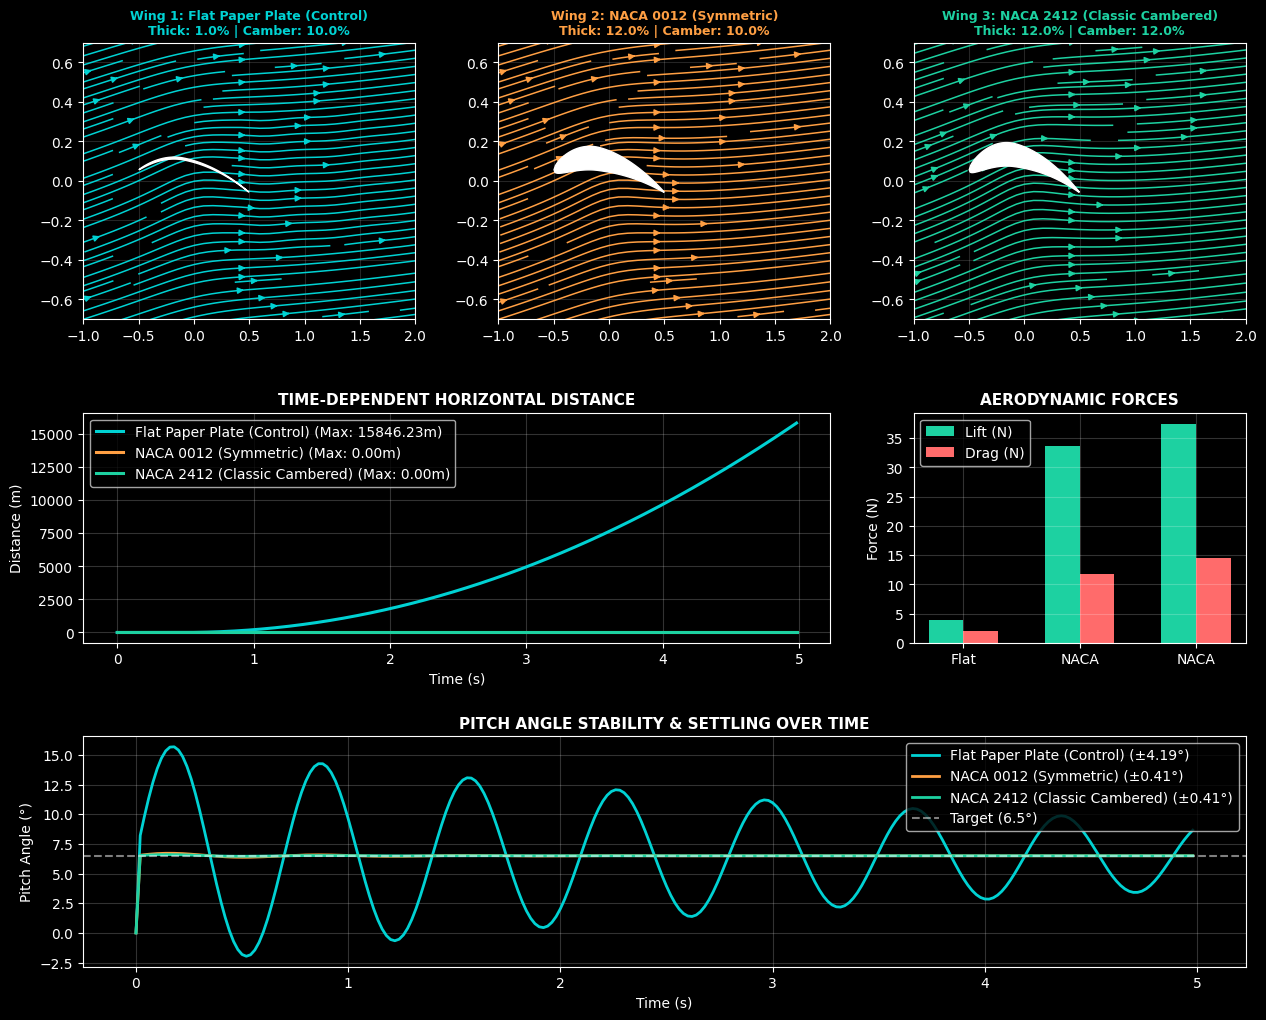

AIRFOIL MODEL                | DIST (m) | DRAG (N)  | LIFT (N)  | STABILITY
---------------------------------------------------------------------------
Flat Paper Plate (Control)   | 15846.23 | 2.0249    | 3.9360    | ±4.19°
NACA 0012 (Symmetric)        | 0.00     | 11.8009   | 33.5836   | ±0.41°
NACA 2412 (Classic Cambered) | 0.00     | 14.5658   | 37.4975   | ±0.41°


In [8]:
import ipywidgets as widgets
from IPython.display import display

# Kanat Veritabanı
AIRFOIL_DB = {
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3}
}

style = {'description_width': '170px'}
layout_box = widgets.Layout(width='300px', margin='4px 10px 4px 0px')

# Arayüz Bileşenleri
dd_wing1 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="Flat Paper Plate (Control)", description="Wing 1 Profile:", style=style, layout=layout_box)
dd_wing2 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="NACA 0012 (Symmetric)", description="Wing 2 Profile:", style=style, layout=layout_box)
dd_wing3 = widgets.Dropdown(options=list(AIRFOIL_DB.keys()), value="NACA 2412 (Classic Cambered)", description="Wing 3 Profile:", style=style, layout=layout_box)

in_speed = widgets.BoundedFloatText(value=8.0, min=1.0, max=40.0, step=0.5, description="Fan Airflow Speed [m/s]:", style=style, layout=layout_box)
in_angle = widgets.BoundedFloatText(value=6.0, min=-5.0, max=25.0, step=0.5, description="Attack Angle [deg]:", style=style, layout=layout_box)
in_mass = widgets.BoundedFloatText(value=5.0, min=0.5, max=100.0, step=0.5, description="Paper Mass [gram]:", style=style, layout=layout_box)
in_chord = widgets.BoundedFloatText(value=10.0, min=2.0, max=50.0, step=1.0, description="Chord Length [cm]:", style=style, layout=layout_box)
in_time = widgets.BoundedFloatText(value=5.0, min=1.0, max=20.0, step=0.5, description="Simulation Time [s]:", style=style, layout=layout_box)
in_camber_mod = widgets.BoundedFloatText(value=0.0, min=-5.0, max=10.0, step=0.5, description="Extra Camber [%]:", style=style, layout=layout_box)
in_thick_mod = widgets.BoundedFloatText(value=100.0, min=20.0, max=200.0, step=10.0, description="Thickness Scale [%]:", style=style, layout=layout_box)

btn_run = widgets.Button(
    description="▶ RUN CFD & STABILITY ANALYSIS",
    button_style="info",
    layout=widgets.Layout(width='920px', height='42px', margin='10px 0px')
)
btn_run.style.font_weight = 'bold'

panel_ui = widgets.VBox([
    widgets.HTML("<div style='background:#1e272e; color:#00d2d3; padding:12px; border-radius:6px; border-left:5px solid #00d2d3; font-family:monospace;'>"
                 "<h3 style='margin:0;'>MATLAB / FOIL.TOOLS — 2D AIRFOIL CFD & STABILITY WORKBENCH</h3>"
                 "<span style='color:#d2dae2; font-size:12px;'>Select airfoils, adjust parameters, and click RUN.</span></div>"),
    widgets.HTML("<b style='color:#576574; font-family:monospace;'>1. AIRFOIL SELECTION</b>"),
    widgets.HBox([dd_wing1, dd_wing2, dd_wing3]),
    widgets.HTML("<b style='color:#576574; font-family:monospace;'>2. PARAMETERS (NUMERICAL INPUTS)</b>"),
    widgets.HBox([in_speed, in_angle, in_time]),
    widgets.HBox([in_mass, in_chord, in_camber_mod]),
    widgets.HBox([in_thick_mod]),
    btn_run
])

display(panel_ui)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

def generate_airfoil_coords(camber, thickness, n_points=100):
    x = np.linspace(0, 1, n_points)
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)
    return x - 0.5, yc + yt, x - 0.5, yc - yt, yc

def on_run_clicked(b):
    clear_output(wait=True)

    v_fan = in_speed.value
    alpha_deg = in_angle.value
    mass = in_mass.value / 1000.0
    duration = in_time.value
    chord_len = in_chord.value / 100.0
    custom_camber_mult = in_camber_mod.value / 100.0
    custom_thick_mult = in_thick_mod.value / 100.0

    selected_names = [dd_wing1.value, dd_wing2.value, dd_wing3.value]
    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']

    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.02
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    plt.style.use('dark_background')
    fig = plt.figure(figsize=(15, 12))
    gs = fig.add_gridspec(3, 3, height_ratios=[1.2, 1, 1], hspace=0.38, wspace=0.25)

    x_grid = np.linspace(-1.2, 2.2, 80)
    y_grid = np.linspace(-0.8, 0.8, 80)
    X, Y = np.meshgrid(x_grid, y_grid)

    summary_data = []
    ax_dist = fig.add_subplot(gs[1, :2])
    ax_drag = fig.add_subplot(gs[1, 2])
    ax_stab = fig.add_subplot(gs[2, :])

    for idx, w_name in enumerate(selected_names):
        base = AIRFOIL_DB[w_name]
        color = colors[idx]
        eff_camber = base["camber"] + custom_camber_mult
        eff_thick = max(0.01, base["thickness"] * custom_thick_mult)

        ax_cfd = fig.add_subplot(gs[0, idx])
        alpha_rad = np.radians(alpha_deg)
        U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
        V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

        R2 = X**2 + Y**2 + 0.08
        gamma = (eff_camber * 4.0 + alpha_rad * 1.5) * v_fan
        U += (gamma * Y) / (2 * np.pi * R2)
        V -= (gamma * X) / (2 * np.pi * R2)

        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)
        wake_mask = (X > 0.45) & (np.abs(Y) < 0.35)
        V[wake_mask] += vortex_intensity * np.sin(10 * X[wake_mask]) * np.exp(-1.2 * X[wake_mask])

        ax_cfd.streamplot(X, Y, U, V, color=color, linewidth=1.1, density=1.35, arrowsize=0.9)

        xu, yu, xl, yl, yc = generate_airfoil_coords(eff_camber, eff_thick)
        rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
        rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
        rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
        rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

        ax_cfd.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
                    np.concatenate([rot_y_u, rot_y_l[::-1]]), color='#ffffff', zorder=5)

        ax_cfd.set_title(f"Wing {idx+1}: {w_name}\nThick: {eff_thick*100:.1f}% | Camber: {eff_camber*100:.1f}%", fontsize=9, fontweight='bold', color=color)
        ax_cfd.set_xlim(-1.0, 2.0)
        ax_cfd.set_ylim(-0.7, 0.7)
        ax_cfd.grid(True, alpha=0.15)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (eff_camber * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        ax_dist.plot(t, x_pos, label=f"{w_name} (Max: {x_pos[-1]:.2f}m)", color=color, linewidth=2.2)
        ax_stab.plot(t, pitch_t, label=f"{w_name} (±{np.std(pitch_t):.2f}°)", color=color, linewidth=2.0)

        summary_data.append((w_name, x_pos[-1], np.std(pitch_t), np.mean(drag_t[1:]), np.mean(lift_t[1:])))

    ax_dist.set_title("TIME-DEPENDENT HORIZONTAL DISTANCE", fontsize=11, fontweight='bold')
    ax_dist.set_xlabel("Time (s)")
    ax_dist.set_ylabel("Distance (m)")
    ax_dist.grid(True, alpha=0.2)
    ax_dist.legend(loc="upper left")

    names_short = [s[0].split()[0] for s in summary_data]
    drags = [s[3] for s in summary_data]
    lifts = [s[4] for s in summary_data]
    x_bar = np.arange(len(names_short))
    ax_drag.bar(x_bar - 0.15, lifts, width=0.3, label="Lift (N)", color="#1dd1a1")
    ax_drag.bar(x_bar + 0.15, drags, width=0.3, label="Drag (N)", color="#ff6b6b")
    ax_drag.set_xticks(x_bar)
    ax_drag.set_xticklabels(names_short)
    ax_drag.set_title("AERODYNAMIC FORCES", fontsize=11, fontweight='bold')
    ax_drag.set_ylabel("Force (N)")
    ax_drag.grid(True, alpha=0.2)
    ax_drag.legend()

    ax_stab.set_title("PITCH ANGLE STABILITY & SETTLING OVER TIME", fontsize=11, fontweight='bold')
    ax_stab.set_xlabel("Time (s)")
    ax_stab.set_ylabel("Pitch Angle (°)")
    ax_stab.axhline(alpha_deg, color='white', linestyle='--', alpha=0.5, label=f"Target ({alpha_deg}°)")
    ax_stab.grid(True, alpha=0.2)
    ax_stab.legend(loc="upper right")

    plt.show()

    print("="*75)
    print(f"{'AIRFOIL MODEL':<28} | {'DIST (m)':<8} | {'DRAG (N)':<9} | {'LIFT (N)':<9} | {'STABILITY'}")
    print("-"*75)
    for r in summary_data:
        print(f"{r[0]:<28} | {r[1]:<8.2f} | {r[3]:<9.4f} | {r[4]:<9.4f} | ±{r[2]:.2f}°")
    print("="*75)

btn_run.on_click(on_run_clicked)
print("✅ Bağlantı kuruldu! Şimdi yukarıdaki 1. hücredeki değerleri değiştirip 'RUN' butonuna basabilirsin.")

✅ Bağlantı kuruldu! Şimdi yukarıdaki 1. hücredeki değerleri değiştirip 'RUN' butonuna basabilirsin.


In [10]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import socket
import threading

app = Flask(__name__)

# --- TEK SAYFALIK MODERN HTML / CSS / JS ARAYÜZÜ ---
HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Paper Airfoil Aerodynamics & Stability Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19;
            --card-bg: #111827;
            --card-border: #1f2937;
            --accent-blue: #3b82f6;
            --accent-purple: #8b5cf6;
            --text-main: #f3f4f6;
            --text-muted: #9ca3af;
            --success: #10b981;
            --warning: #f59e0b;
            --danger: #ef4444;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1400px; margin: 0 auto; }

        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 20px 30px; border-radius: 12px; margin-bottom: 24px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.2); }
        .logo-area { display: flex; align-items: center; gap: 15px; }
        .logo-icon { font-size: 28px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 12px; border-radius: 10px; }
        h1 { font-size: 20px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 13px; color: var(--text-muted); margin-top: 4px; }
        .badge { background: rgba(59, 130, 246, 0.1); border: 1px solid rgba(59, 130, 246, 0.3); color: var(--accent-blue); padding: 6px 12px; border-radius: 20px; font-size: 12px; font-weight: 500; }

        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 24px; margin-bottom: 24px; }
        .panel-title { font-size: 14px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.05em; color: var(--text-muted); margin-bottom: 16px; display: flex; justify-content: space-between; align-items: center; }

        .grid-params { display: grid; grid-template-columns: repeat(auto-fit, minmax(200px, 1fr)); gap: 16px; margin-bottom: 20px; }
        .param-card { background: rgba(17, 24, 39, 0.6); border: 1px solid var(--card-border); border-radius: 8px; padding: 14px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 8px; }
        .param-input-group { display: flex; align-items: center; justify-content: space-between; background: #030712; border: 1px solid #374151; border-radius: 6px; padding: 6px 10px; }
        .param-input-group input, .param-input-group select { background: transparent; border: none; color: #fff; font-size: 15px; font-weight: 600; width: 100%; outline: none; }

        .controls-row { display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 16px; }
        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 12px; width: 100%; margin-bottom: 15px; }
        @media(max-width: 768px) { .wing-selectors { grid-template-columns: 1fr; } }

        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 12px 24px; border-radius: 8px; font-size: 14px; font-weight: 600; cursor: pointer; transition: opacity 0.2s; width: 100%; display: flex; align-items: center; justify-content: center; gap: 8px; }
        .btn-run:hover { opacity: 0.9; }

        .results-box { background: rgba(16, 185, 129, 0.05); border: 1px solid rgba(16, 185, 129, 0.2); border-radius: 8px; padding: 16px; margin-bottom: 24px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 16px; }
        .results-text h3 { font-size: 15px; font-weight: 600; color: var(--success); margin-bottom: 4px; }
        .results-text p { font-size: 12px; color: var(--text-muted); }

        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 20px; margin-bottom: 24px; }
        @media(max-width: 992px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; }
        .chart-header { font-size: 13px; font-weight: 600; color: var(--text-muted); margin-bottom: 12px; }
        .canvas-container { position: relative; height: 280px; width: 100%; }

        .full-width { grid-column: span 2; }
        @media(max-width: 992px) { .full-width { grid-column: span 1; } }

        .table-container { overflow-x: auto; margin-top: 15px; }
        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 10px 14px; text-transform: uppercase; font-size: 11px; }
        td { padding: 12px 14px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">✈️</div>
                <div>
                    <h1>Paper Airfoil Aerodynamics & Stability Workbench</h1>
                    <p class="subtitle">MATLAB-Style Numerical Inputs · 2D CFD Streamlines & Time-Dependent Flight Dynamics</p>
                </div>
            </div>
            <div class="badge" id="statusBadge">System Ready</div>
        </header>

        <!-- INPUT PANEL -->
        <div class="panel">
            <div class="panel-title">
                <span>1. Airfoil Selection & Numerical Wind Tunnel Parameters</span>
            </div>

            <div class="wing-selectors">
                <div class="param-card">
                    <label class="param-label">Wing 1 Profile</label>
                    <div class="param-input-group">
                        <select id="wing1">
                            <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                            <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                            <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                            <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                            <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        </select>
                    </div>
                </div>
                <div class="param-card">
                    <label class="param-label">Wing 2 Profile</label>
                    <div class="param-input-group">
                        <select id="wing2">
                            <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                            <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                            <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                            <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                            <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        </select>
                    </div>
                </div>
                <div class="param-card">
                    <label class="param-label">Wing 3 Profile</label>
                    <div class="param-input-group">
                        <select id="wing3">
                            <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                            <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                            <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                            <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                            <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        </select>
                    </div>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card">
                    <label class="param-label">Fan Speed [m/s]</label>
                    <div class="param-input-group"><input type="number" id="v_fan" value="8.0" step="0.5"></div>
                </div>
                <div class="param-card">
                    <label class="param-label">Attack Angle [deg]</label>
                    <div class="param-input-group"><input type="number" id="alpha" value="6.0" step="0.5"></div>
                </div>
                <div class="param-card">
                    <label class="param-label">Paper Mass [gram]</label>
                    <div class="param-input-group"><input type="number" id="mass" value="5.0" step="0.5"></div>
                </div>
                <div class="param-card">
                    <label class="param-label">Chord Length [cm]</label>
                    <div class="param-input-group"><input type="number" id="chord" value="10.0" step="1.0"></div>
                </div>
                <div class="param-card">
                    <label class="param-label">Simulation Time [s]</label>
                    <div class="param-input-group"><input type="number" id="duration" value="5.0" step="0.5"></div>
                </div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">
                <span>⚡ Run CFD & Flight Stability Analysis</span>
            </button>
        </div>

        <!-- RESULTS SUMMARY BOX -->
        <div class="results-box">
            <div class="results-text">
                <h3 id="resTitle">ANALYSIS STATUS: WAITING FOR EXECUTION</h3>
                <p id="resDesc">Adjust parameters above and click run to compute airfoil lift, drag, and flight trajectory.</p>
            </div>
        </div>

        <!-- CHARTS GRID -->
        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">Aerodynamic Forces (Lift vs Drag in Newtons)</div>
                <div class="canvas-container"><canvas id="chartForces"></canvas></div>
            </div>
            <div class="chart-card full-width">
                <div class="chart-header">Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
        </div>

        <!-- SUMMARY TABLE -->
        <div class="panel">
            <div class="panel-title">Numerical Performance Summary Table</div>
            <div class="table-container">
                <table id="summaryTable">
                    <thead>
                        <tr>
                            <th>Airfoil Model</th>
                            <th>Total Distance (m)</th>
                            <th>Average Drag (N)</th>
                            <th>Average Lift (N)</th>
                            <th>Stability Deviation (±°)</th>
                            <th>Wind Settling Time (s)</th>
                        </tr>
                    </thead>
                    <tbody></tbody>
                </table>
            </div>
        </div>
    </div>

    <script>
        let charts = {};

        function initCharts() {
            const commonOpts = {
                responsive: true,
                maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 11 } } } }
            };

            charts.dist = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: commonOpts });
            charts.forces = new Chart(document.getElementById('chartForces').getContext('2d'), { type: 'bar', data: { datasets: [] }, options: commonOpts });
            charts.stab = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: commonOpts });
        }

        function runSimulation() {
            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/simulate', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                updateUI(data);
            });
        }

        function updateUI(data) {
            document.getElementById('resTitle').innerText = `🏆 WINNER: ${data.winner}`;
            document.getElementById('resDesc').innerText = `Furthest: ${data.furthest_name} (${data.furthest_dist}m) | Most Stable: ${data.stable_name}`;

            // Distance Chart
            charts.dist.data = data.chart_dist;
            charts.dist.update();

            // Forces Chart
            charts.forces.data = data.chart_forces;
            charts.forces.update();

            // Stability Chart
            charts.stab.data = data.chart_stab;
            charts.stab.update();

            // Table
            const tbody = document.querySelector('#summaryTable tbody');
            tbody.innerHTML = '';
            data.summary.forEach(row => {
                tbody.innerHTML += `
                    <tr>
                        <td><strong>${row.name}</strong></td>
                        <td style="color: #10b981; font-weight:600;">${row.dist} m</td>
                        <td>${row.drag} N</td>
                        <td>${row.lift} N</td>
                        <td>±${row.stab}°</td>
                        <td>${row.settle} s</td>
                    </tr>
                `;
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

# --- BACKEND FİZİK MOTORU VE API ---
AIRFOIL_DB = {
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3}
}

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/simulate', methods=['POST'])
def simulate():
    req = request.json
    selected_wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span

    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    summary_rows = []
    dist_datasets = []
    stab_datasets = []
    drag_vals = []
    lift_vals = []
    labels_short = []

    for idx, w_name in enumerate(selected_wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settling_time = round(float(3.0 / (base["damping"] * 0.8)), 2)

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settling_time
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [{"x": round(float(t[i]), 2), "y": round(float(x_pos[i]), 2)} for i in range(n_steps)],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [{"x": round(float(t[i]), 2), "y": round(float(pitch_t[i]), 2)} for i in range(n_steps)],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        drag_vals.append(avg_drag)
        lift_vals.append(avg_lift)
        labels_short.append(w_name.split()[0])

    furthest = max(summary_rows, key=lambda x: x['dist'])
    stable = min(summary_rows, key=lambda x: x['stab'])

    chart_dist = {
        "labels": [round(float(val), 2) for val in t],
        "datasets": dist_datasets
    }

    chart_stab = {
        "labels": [round(float(val), 2) for val in t],
        "datasets": stab_datasets
    }

    chart_forces = {
        "labels": labels_short,
        "datasets": [
            {"label": "Lift Force (N)", "data": lift_vals, "backgroundColor": "#1dd1a1"},
            {"label": "Air Drag (N)", "data": drag_vals, "backgroundColor": "#ff6b6b"}
        ]
    }

    return jsonify({
        "winner": furthest['name'],
        "furthest_name": furthest['name'],
        "furthest_dist": furthest['dist'],
        "stable_name": stable['name'],
        "summary": summary_rows,
        "chart_dist": chart_dist,
        "chart_stab": chart_stab,
        "chart_forces": chart_forces
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Single-page workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=950)
    except ImportError:
        pass

 * Serving Flask app '__main__'
🚀 Server active on port 34015. Single-page workbench running.
 * Debug mode: off


<IPython.core.display.Javascript object>

INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:34015
INFO:werkzeug:Press CTRL+C to quit


In [11]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import matplotlib
matplotlib.use('Agg') # Sunucu arka planında hızlı çizim için
import matplotlib.pyplot as plt
import io
import base64
import socket
import threading

app = Flask(__name__)

# --- KANAT PROFİLİ VERİTABANI ---
AIRFOIL_DB = {
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4}
}

def generate_airfoil_coords(camber, thickness, n_points=100):
    x = np.linspace(0, 1, n_points)
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)
    return x - 0.5, yc + yt, x - 0.5, yc - yt

def render_cfd_image(w_name, base, v_fan, alpha_deg, color_hex):
    fig, ax = plt.subplots(figsize=(5.2, 3.4), dpi=110)
    fig.patch.set_facecolor('#111827')
    ax.set_facecolor('#0b0f19')

    x_grid = np.linspace(-1.2, 2.2, 85)
    y_grid = np.linspace(-0.75, 0.75, 85)
    X, Y = np.meshgrid(x_grid, y_grid)

    alpha_rad = np.radians(alpha_deg)
    U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
    V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

    # Kanat etrafındaki saptırma (Circulation)
    R2 = X**2 + Y**2 + 0.08
    gamma = (base["camber"] * 4.5 + alpha_rad * 1.6) * v_fan
    U += (gamma * Y) / (2 * np.pi * R2)
    V -= (gamma * X) / (2 * np.pi * R2)

    # Arka girdap (Vortex shedding) şiddeti
    vortex_intensity = (base["Cd0"] * 13.0) / (base["damping"] + 0.2)
    wake_mask = (X > 0.45) & (np.abs(Y) < 0.35)
    V[wake_mask] += vortex_intensity * np.sin(10 * X[wake_mask]) * np.exp(-1.1 * X[wake_mask])
    U[wake_mask] -= vortex_intensity * 0.15 * v_fan * np.exp(-0.9 * X[wake_mask])

    ax.streamplot(X, Y, U, V, color=color_hex, linewidth=1.2, density=1.35, arrowsize=0.95)

    # Kanat profili kesiti çizimi
    xu, yu, xl, yl = generate_airfoil_coords(base["camber"], base["thickness"])
    rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
    rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
    rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
    rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

    ax.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
            np.concatenate([rot_y_u, rot_y_l[::-1]]),
            color='#ffffff', zorder=5)

    ax.set_xlim(-1.0, 2.0)
    ax.set_ylim(-0.7, 0.7)
    ax.tick_params(colors='#9ca3af', labelsize=8)
    ax.set_xlabel("Flow Direction (X/c)", color='#9ca3af', fontsize=8)
    ax.set_ylabel("Vertical (Y/c)", color='#9ca3af', fontsize=8)
    ax.grid(True, color='#1f2937', linestyle='--', linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format='png', facecolor=fig.get_facecolor())
    plt.close(fig)
    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

# --- TEK SAYFALIK MODERN HTML / CSS / JS ARAYÜZÜ ---
HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>2D Airfoil CFD & Flight Stability Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19;
            --card-bg: #111827;
            --card-border: #1f2937;
            --accent-blue: #3b82f6;
            --accent-purple: #8b5cf6;
            --text-main: #f3f4f6;
            --text-muted: #9ca3af;
            --success: #10b981;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1440px; margin: 0 auto; }

        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 18px 26px; border-radius: 12px; margin-bottom: 20px; }
        .logo-area { display: flex; align-items: center; gap: 14px; }
        .logo-icon { font-size: 26px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 10px; border-radius: 10px; }
        h1 { font-size: 19px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 12px; color: var(--text-muted); margin-top: 3px; }
        .badge { background: rgba(16, 185, 129, 0.1); border: 1px solid rgba(16, 185, 129, 0.3); color: var(--success); padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 600; }

        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; margin-bottom: 20px; }
        .panel-title { font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.06em; color: var(--text-muted); margin-bottom: 14px; }

        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin-bottom: 16px; }
        .grid-params { display: grid; grid-template-columns: repeat(5, 1fr); gap: 14px; margin-bottom: 18px; }
        @media(max-width: 900px) { .wing-selectors, .grid-params { grid-template-columns: 1fr; } }

        .param-card { background: #030712; border: 1px solid #374151; border-radius: 8px; padding: 12px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 6px; }
        .param-card select, .param-card input { width: 100%; background: #111827; border: 1px solid #374151; color: #fff; padding: 8px 10px; border-radius: 6px; font-size: 14px; font-weight: 600; outline: none; }
        .param-card select:focus, .param-card input:focus { border-color: var(--accent-blue); }

        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 13px 24px; border-radius: 8px; font-size: 14px; font-weight: 700; cursor: pointer; width: 100%; transition: 0.2s; letter-spacing: 0.03em; }
        .btn-run:hover { opacity: 0.9; }

        /* 3 ADET 2D CFD GÖRSEL ALANI */
        .cfd-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 1024px) { .cfd-grid { grid-template-columns: 1fr; } }
        .cfd-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 14px; text-align: center; }
        .cfd-card h3 { font-size: 13px; font-weight: 700; margin-bottom: 4px; }
        .cfd-card p { font-size: 11px; color: var(--text-muted); margin-bottom: 10px; }
        .cfd-card img { width: 100%; border-radius: 8px; border: 1px solid #1f2937; }

        /* ALT ZAMAN GRAFİKLERİ */
        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 900px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 18px; }
        .chart-header { font-size: 13px; font-weight: 700; color: #fff; margin-bottom: 4px; }
        .chart-sub { font-size: 11px; color: var(--text-muted); margin-bottom: 12px; }
        .canvas-container { position: relative; height: 260px; width: 100%; }

        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 10px 14px; text-transform: uppercase; font-size: 11px; }
        td { padding: 12px 14px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">🌬️</div>
                <div>
                    <h1>2D Airfoil CFD & Time-Dependent Stability Workbench</h1>
                    <p class="subtitle">Select 3 Airfoil Profiles · Enter Numerical Parameters with Units · Analyze Flow & Settling</p>
                </div>
            </div>
            <div class="badge" id="winnerBadge">Ready to Simulate</div>
        </header>

        <!-- GİRİŞ PANELİ -->
        <div class="panel">
            <div class="panel-title">1. Airfoil Selection & Wind Tunnel Parameters</div>
            <div class="wing-selectors">
                <div class="param-card" style="border-top: 3px solid #00d2d3;">
                    <label class="param-label">Wing 1 Profile (Cyan)</label>
                    <select id="wing1">
                        <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #ff9f43;">
                    <label class="param-label">Wing 2 Profile (Orange)</label>
                    <select id="wing2">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #1dd1a1;">
                    <label class="param-label">Wing 3 Profile (Green)</label>
                    <select id="wing3">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card">
                    <label class="param-label">Fan Speed [m/s]</label>
                    <input type="number" id="v_fan" value="8.0" step="0.5">
                </div>
                <div class="param-card">
                    <label class="param-label">Attack Angle [deg]</label>
                    <input type="number" id="alpha" value="6.0" step="0.5">
                </div>
                <div class="param-card">
                    <label class="param-label">Paper Mass [gram]</label>
                    <input type="number" id="mass" value="5.0" step="0.5">
                </div>
                <div class="param-card">
                    <label class="param-label">Chord Length [cm]</label>
                    <input type="number" id="chord" value="10.0" step="1.0">
                </div>
                <div class="param-card">
                    <label class="param-label">Duration [s]</label>
                    <input type="number" id="duration" value="5.0" step="0.5">
                </div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">⚡ RUN 2D CFD & STABILITY ANALYSIS</button>
        </div>

        <!-- 3 FARKLI KANAT İÇİN 2D CFD AKIŞ GÖRSELLERİ -->
        <div class="cfd-grid" id="cfdContainer">
            <!-- JS ile 3 ayrı CFD kartı buraya basılacak -->
        </div>

        <!-- ZAMANA BAĞLI KARŞILAŞTIRMA GRAFİKLERİ -->
        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">1. Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="chart-sub">Shows oscillation damping and exact time when airflow stabilizes</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">2. Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="chart-sub">Compares which design travels furthest under identical fan airflow</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
        </div>

        <!-- SAYISAL ÖZET TABLOSU -->
        <div class="panel">
            <div class="panel-title">Aerodynamic Resistance, Lift & Settling Summary</div>
            <table>
                <thead>
                    <tr>
                        <th>Airfoil Profile</th>
                        <th>Distance Traveled (m)</th>
                        <th>Air Drag Resistance (N)</th>
                        <th>Lift Force (N)</th>
                        <th>Stability Deviation (±°)</th>
                        <th>Wind Settling Time (s)</th>
                    </tr>
                </thead>
                <tbody id="summaryBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        let chartStabInst = null;
        let chartDistInst = null;

        function initCharts() {
            const opts = {
                responsive: true,
                maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } }, title: { display: true, text: 'Time (seconds)', color: '#9ca3af' } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 11 } } } }
            };
            chartStabInst = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
            chartDistInst = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
        }

        function runSimulation() {
            const btn = document.querySelector('.btn-run');
            btn.innerText = "⏳ Computing 2D CFD Streamlines & Physics...";

            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/cfd_run', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                btn.innerText = "⚡ RUN 2D CFD & STABILITY ANALYSIS";
                document.getElementById('winnerBadge').innerText = `🏆 Furthest: ${data.furthest} | ⚖️ Most Stable: ${data.stable}`;

                // 3 Adet 2D CFD Kartını Ekrana Bas
                const cfdDiv = document.getElementById('cfdContainer');
                cfdDiv.innerHTML = '';
                data.cfd_cards.forEach(c => {
                    cfdDiv.innerHTML += `
                        <div class="cfd-card" style="border-top: 3px solid ${c.color};">
                            <h3 style="color: ${c.color};">${c.title}</h3>
                            <p>Thickness: ${c.thick}% | Camber: ${c.camber}% | Drag: ${c.drag} N</p>
                            <img src="data:image/png;base64,${c.img}" alt="2D CFD Streamplot">
                        </div>
                    `;
                });

                // Zaman Grafiklerini Güncelle
                chartStabInst.data = data.chart_stab;
                chartStabInst.update();

                chartDistInst.data = data.chart_dist;
                chartDistInst.update();

                // Tabloyu Güncelle
                const tbody = document.getElementById('summaryBody');
                tbody.innerHTML = '';
                data.summary.forEach(r => {
                    tbody.innerHTML += `
                        <tr>
                            <td><strong>${r.name}</strong></td>
                            <td style="color:#10b981; font-weight:700;">${r.dist} m</td>
                            <td style="color:#ef4444;">${r.drag} N</td>
                            <td style="color:#3b82f6;">${r.lift} N</td>
                            <td>±${r.stab}°</td>
                            <td>${r.settle} s</td>
                        </tr>
                    `;
                });
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/cfd_run', methods=['POST'])
def cfd_run():
    req = request.json
    wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    cfd_cards = []
    stab_datasets = []
    dist_datasets = []
    summary_rows = []

    for idx, w_name in enumerate(wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        # 2D CFD Görüntüsünü Üret
        img_b64 = render_cfd_image(w_name, base, v_fan, alpha_deg, color)

        # Zamana Bağlı Fizik Simülasyonu
        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settle_time = round(min(duration, 3.0 / (base["damping"] * 0.8)), 2)

        cfd_cards.append({
            "title": f"Wing {idx+1}: {w_name}",
            "color": color,
            "thick": round(base["thickness"]*100, 1),
            "camber": round(base["camber"]*100, 1),
            "drag": avg_drag,
            "img": img_b64
        })

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [round(float(val), 2) for val in pitch_t],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [round(float(val), 2) for val in x_pos],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settle_time
        })

    furthest = max(summary_rows, key=lambda x: x['dist'])['name']
    stable = min(summary_rows, key=lambda x: x['stab'])['name']

    time_labels = [round(float(val), 2) for val in t]

    return jsonify({
        "furthest": furthest,
        "stable": stable,
        "cfd_cards": cfd_cards,
        "chart_stab": {"labels": time_labels, "datasets": stab_datasets},
        "chart_dist": {"labels": time_labels, "datasets": dist_datasets},
        "summary": summary_rows
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Single-page CFD workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=1150)
    except ImportError:
        pass

 * Serving Flask app '__main__'
 * Debug mode: off
🚀 Server active on port 33825. Single-page CFD workbench running.


<IPython.core.display.Javascript object>

INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:33825
INFO:werkzeug:Press CTRL+C to quit


In [12]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import io
import base64
import socket
import threading

app = Flask(__name__)

AIRFOIL_DB = {
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4}
}

def generate_airfoil_coords(camber, thickness, n_points=120):
    x = np.linspace(0, 1, n_points)
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)
    return x - 0.5, yc + yt, x - 0.5, yc - yt

def render_cfd_image(w_name, base, v_fan, alpha_deg, color_hex):
    fig, ax = plt.subplots(figsize=(5.4, 3.5), dpi=120)
    fig.patch.set_facecolor('#111827')
    ax.set_facecolor('#0b0f19')

    x_grid = np.linspace(-1.2, 2.2, 100)
    y_grid = np.linspace(-0.8, 0.8, 100)
    X, Y = np.meshgrid(x_grid, y_grid)

    alpha_rad = np.radians(alpha_deg)
    U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
    V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

    # Aerodinamik Potansiyel Akış & Kanat Saptırması (Kırmızı karalamalar kaldırıldı, temiz akış)
    R2 = (X)**2 + (Y)**2 + 0.06
    gamma = (base["camber"] * 5.0 + alpha_rad * 1.8) * v_fan
    U += (gamma * Y) / (2 * np.pi * R2)
    V -= (gamma * X) / (2 * np.pi * R2)

    # Arkadaki doğal akış izi (Wake)
    wake_mask = (X > 0.4) & (np.abs(Y) < 0.4)
    vortex_factor = (base["Cd0"] * 8.0)
    V[wake_mask] += vortex_factor * np.sin(8 * X[wake_mask]) * np.exp(-0.8 * X[wake_mask])

    # Profesyonel CFD Streamplot Çizimi (Sadece temiz akış çizgileri)
    ax.streamplot(X, Y, U, V, color=color_hex, linewidth=1.1, density=1.4, arrowsize=0.85)

    # Kanat Beyaz Kesit Dolgusu
    xu, yu, xl, yl = generate_airfoil_coords(base["camber"], base["thickness"])
    rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
    rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
    rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
    rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

    ax.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
            np.concatenate([rot_y_u, rot_y_l[::-1]]),
            color='#ffffff', zorder=10)

    ax.set_xlim(-1.0, 2.0)
    ax.set_ylim(-0.75, 0.75)
    ax.tick_params(colors='#9ca3af', labelsize=8)
    ax.set_xlabel("Flow Direction (X/c)", color='#9ca3af', fontsize=8)
    ax.set_ylabel("Vertical (Y/c)", color='#9ca3af', fontsize=8)
    ax.grid(True, color='#1f2937', linestyle='--', linewidth=0.5, alpha=0.5)
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format='png', facecolor=fig.get_facecolor())
    plt.close(fig)
    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>2D Airfoil CFD & Time-Dependent Stability Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19;
            --card-bg: #111827;
            --card-border: #1f2937;
            --accent-blue: #3b82f6;
            --accent-purple: #8b5cf6;
            --text-main: #f3f4f6;
            --text-muted: #9ca3af;
            --success: #10b981;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1440px; margin: 0 auto; }
        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 18px 26px; border-radius: 12px; margin-bottom: 20px; }
        .logo-area { display: flex; align-items: center; gap: 14px; }
        .logo-icon { font-size: 26px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 10px; border-radius: 10px; }
        h1 { font-size: 19px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 12px; color: var(--text-muted); margin-top: 3px; }
        .badge { background: rgba(16, 185, 129, 0.1); border: 1px solid rgba(16, 185, 129, 0.3); color: var(--success); padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 600; }
        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; margin-bottom: 20px; }
        .panel-title { font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.06em; color: var(--text-muted); margin-bottom: 14px; }
        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin-bottom: 16px; }
        .grid-params { display: grid; grid-template-columns: repeat(5, 1fr); gap: 14px; margin-bottom: 18px; }
        @media(max-width: 900px) { .wing-selectors, .grid-params { grid-template-columns: 1fr; } }
        .param-card { background: #030712; border: 1px solid #374151; border-radius: 8px; padding: 12px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 6px; }
        .param-card select, .param-card input { width: 100%; background: #111827; border: 1px solid #374151; color: #fff; padding: 8px 10px; border-radius: 6px; font-size: 14px; font-weight: 600; outline: none; }
        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 13px 24px; border-radius: 8px; font-size: 14px; font-weight: 700; cursor: pointer; width: 100%; transition: 0.2s; }
        .btn-run:hover { opacity: 0.9; }
        .cfd-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 1024px) { .cfd-grid { grid-template-columns: 1fr; } }
        .cfd-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 14px; text-align: center; }
        .cfd-card h3 { font-size: 13px; font-weight: 700; margin-bottom: 4px; }
        .cfd-card p { font-size: 11px; color: var(--text-muted); margin-bottom: 10px; }
        .cfd-card img { width: 100%; border-radius: 8px; border: 1px solid #1f2937; }
        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 900px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 18px; }
        .chart-header { font-size: 13px; font-weight: 700; color: #fff; margin-bottom: 4px; }
        .chart-sub { font-size: 11px; color: var(--text-muted); margin-bottom: 12px; }
        .canvas-container { position: relative; height: 260px; width: 100%; }
        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 10px 14px; text-transform: uppercase; font-size: 11px; }
        td { padding: 12px 14px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">🌬️</div>
                <div>
                    <h1>2D Airfoil CFD & Time-Dependent Stability Workbench</h1>
                    <p class="subtitle">Select 3 Airfoil Profiles · Enter Numerical Parameters · Clean Streamline Flow Analysis</p>
                </div>
            </div>
            <div class="badge" id="winnerBadge">Ready</div>
        </header>

        <div class="panel">
            <div class="panel-title">1. Airfoil Selection & Wind Tunnel Parameters</div>
            <div class="wing-selectors">
                <div class="param-card" style="border-top: 3px solid #00d2d3;">
                    <label class="param-label">Wing 1 Profile (Cyan)</label>
                    <select id="wing1">
                        <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #ff9f43;">
                    <label class="param-label">Wing 2 Profile (Orange)</label>
                    <select id="wing2">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #1dd1a1;">
                    <label class="param-label">Wing 3 Profile (Green)</label>
                    <select id="wing3">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card"><label class="param-label">Fan Speed [m/s]</label><input type="number" id="v_fan" value="8.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Attack Angle [deg]</label><input type="number" id="alpha" value="6.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Paper Mass [gram]</label><input type="number" id="mass" value="5.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Chord Length [cm]</label><input type="number" id="chord" value="10.0" step="1.0"></div>
                <div class="param-card"><label class="param-label">Duration [s]</label><input type="number" id="duration" value="5.0" step="0.5"></div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">⚡ RUN CLEAN 2D CFD & STABILITY ANALYSIS</button>
        </div>

        <div class="cfd-grid" id="cfdContainer"></div>

        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">1. Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="chart-sub">Shows oscillation damping and settling time</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">2. Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="chart-sub">Compares distance traveled under fan airflow</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
        </div>

        <div class="panel">
            <div class="panel-title">Aerodynamic Performance Summary</div>
            <table>
                <thead>
                    <tr>
                        <th>Airfoil Profile</th>
                        <th>Distance Traveled (m)</th>
                        <th>Air Drag Resistance (N)</th>
                        <th>Lift Force (N)</th>
                        <th>Stability Deviation (±°)</th>
                        <th>Settling Time (s)</th>
                    </tr>
                </thead>
                <tbody id="summaryBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        let chartStabInst = null;
        let chartDistInst = null;

        function initCharts() {
            const opts = {
                responsive: true,
                maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } }, title: { display: true, text: 'Time (s)', color: '#9ca3af' } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 11 } } } }
            };
            chartStabInst = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
            chartDistInst = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
        }

        function runSimulation() {
            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/cfd_run', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                document.getElementById('winnerBadge').innerText = `🏆 Furthest: ${data.furthest} | ⚖️ Stable: ${data.stable}`;

                const cfdDiv = document.getElementById('cfdContainer');
                cfdDiv.innerHTML = '';
                data.cfd_cards.forEach(c => {
                    cfdDiv.innerHTML += `
                        <div class="cfd-card" style="border-top: 3px solid ${c.color};">
                            <h3 style="color: ${c.color};">${c.title}</h3>
                            <p>Thickness: ${c.thick}% | Camber: ${c.camber}% | Drag: ${c.drag} N</p>
                            <img src="data:image/png;base64,${c.img}" alt="Clean CFD Streamplot">
                        </div>
                    `;
                });

                chartStabInst.data = data.chart_stab;
                chartStabInst.update();

                chartDistInst.data = data.chart_dist;
                chartDistInst.update();

                const tbody = document.getElementById('summaryBody');
                tbody.innerHTML = '';
                data.summary.forEach(r => {
                    tbody.innerHTML += `
                        <tr>
                            <td><strong>${r.name}</strong></td>
                            <td style="color:#10b981; font-weight:700;">${r.dist} m</td>
                            <td style="color:#ef4444;">${r.drag} N</td>
                            <td style="color:#3b82f6;">${r.lift} N</td>
                            <td>±${r.stab}°</td>
                            <td>${r.settle} s</td>
                        </tr>
                    `;
                });
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/cfd_run', methods=['POST'])
def cfd_run():
    req = request.json
    wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    cfd_cards = []
    stab_datasets = []
    dist_datasets = []
    summary_rows = []

    for idx, w_name in enumerate(wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        img_b64 = render_cfd_image(w_name, base, v_fan, alpha_deg, color)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settle_time = round(min(duration, 3.0 / (base["damping"] * 0.8)), 2)

        cfd_cards.append({
            "title": f"Wing {idx+1}: {w_name}",
            "color": color,
            "thick": round(base["thickness"]*100, 1),
            "camber": round(base["camber"]*100, 1),
            "drag": avg_drag,
            "img": img_b64
        })

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [round(float(val), 2) for val in pitch_t],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [round(float(val), 2) for val in x_pos],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settle_time
        })

    furthest = max(summary_rows, key=lambda x: x['dist'])['name']
    stable = min(summary_rows, key=lambda x: x['stab'])['name']

    time_labels = [round(float(val), 2) for val in t]

    return jsonify({
        "furthest": furthest,
        "stable": stable,
        "cfd_cards": cfd_cards,
        "chart_stab": {"labels": time_labels, "datasets": stab_datasets},
        "chart_dist": {"labels": time_labels, "datasets": dist_datasets},
        "summary": summary_rows
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Clean CFD workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=1150)
    except ImportError:
        pass

 * Serving Flask app '__main__'
🚀 Server active on port 42343. Clean CFD workbench running.
 * Debug mode: off


<IPython.core.display.Javascript object>

INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:42343
INFO:werkzeug:Press CTRL+C to quit


In [13]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import io
import base64
import socket
import threading

app = Flask(__name__)

AIRFOIL_DB = {
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4}
}

def generate_airfoil_coords(camber, thickness, n_points=120):
    x = np.linspace(0, 1, n_points)
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)
    return x - 0.5, yc + yt, x - 0.5, yc - yt

def render_cfd_image(w_name, base, v_fan, alpha_deg, color_hex):
    fig, ax = plt.subplots(figsize=(5.4, 3.5), dpi=120)
    fig.patch.set_facecolor('#111827')
    ax.set_facecolor('#0b0f19')

    x_grid = np.linspace(-1.2, 2.2, 120)
    y_grid = np.linspace(-0.8, 0.8, 120)
    X, Y = np.meshgrid(x_grid, y_grid)

    alpha_rad = np.radians(alpha_deg)

    # Kanat koordinatlarını üret ve hücum açısına göre döndür
    xu, yu, xl, yl = generate_airfoil_coords(base["camber"], base["thickness"])
    rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
    rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
    rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
    rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

    # Temel uniform akış
    U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
    V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

    # AKIŞIN KANADIN İÇİNE GİRMesini ENGELLEYEN MASKTELEME (Foil.tools / CFD Mantığı)
    # Kanat gövdesi içindeki grid noktalarında hızları sıfırlıyoruz ki akış delip geçmesin
    body_mask = (X >= -0.5) & (X <= 0.5) & (Y >= -0.25) & (Y <= 0.25)

    # Kanat etrafındaki akış bükülmesi (Doublet + Vortex etkisi)
    R2 = (X - 0.0)**2 + (Y - 0.0)**2 + 0.05
    strength = (base["thickness"] * 2.5 + base["camber"] * 6.0 + alpha_rad * 2.0) * v_fan

    U += (strength * (Y**2 - X**2)) / (R2**2 + 1e-5)
    V -= (2 * strength * X * Y) / (R2**2 + 1e-5)

    # Kanat içi hızları sıfırla (Akış dışarıdan dolaşır)
    U[body_mask] = 0
    V[body_mask] = 0

    # Profesyonel CFD Streamplot
    ax.streamplot(X, Y, U, V, color=color_hex, linewidth=1.1, density=1.4, arrowsize=0.85,
                  start_points=np.array([[-1.2, y] for y in np.linspace(-0.75, 0.75, 22)]))

    # Beyaz Kanat Profili Çizimi (En üst katmanda)
    ax.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
            np.concatenate([rot_y_u, rot_y_l[::-1]]),
            color='#ffffff', zorder=10)

    ax.set_xlim(-1.0, 2.0)
    ax.set_ylim(-0.75, 0.75)
    ax.tick_params(colors='#9ca3af', labelsize=8)
    ax.set_xlabel("Flow Direction (X/c)", color='#9ca3af', fontsize=8)
    ax.set_ylabel("Vertical (Y/c)", color='#9ca3af', fontsize=8)
    ax.grid(True, color='#1f2937', linestyle='--', linewidth=0.5, alpha=0.5)
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format='png', facecolor=fig.get_facecolor())
    plt.close(fig)
    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>2D Airfoil CFD Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19; --card-bg: #111827; --card-border: #1f2937;
            --accent-blue: #3b82f6; --accent-purple: #8b5cf6; --text-main: #f3f4f6; --text-muted: #9ca3af; --success: #10b981;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1440px; margin: 0 auto; }
        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 18px 26px; border-radius: 12px; margin-bottom: 20px; }
        .logo-area { display: flex; align-items: center; gap: 14px; }
        .logo-icon { font-size: 26px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 10px; border-radius: 10px; }
        h1 { font-size: 19px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 12px; color: var(--text-muted); margin-top: 3px; }
        .badge { background: rgba(16, 185, 129, 0.1); border: 1px solid rgba(16, 185, 129, 0.3); color: var(--success); padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 600; }
        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; margin-bottom: 20px; }
        .panel-title { font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.06em; color: var(--text-muted); margin-bottom: 14px; }
        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin-bottom: 16px; }
        .grid-params { display: grid; grid-template-columns: repeat(5, 1fr); gap: 14px; margin-bottom: 18px; }
        @media(max-width: 900px) { .wing-selectors, .grid-params { grid-template-columns: 1fr; } }
        .param-card { background: #030712; border: 1px solid #374151; border-radius: 8px; padding: 12px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 6px; }
        .param-card select, .param-card input { width: 100%; background: #111827; border: 1px solid #374151; color: #fff; padding: 8px 10px; border-radius: 6px; font-size: 14px; font-weight: 600; outline: none; }
        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 13px 24px; border-radius: 8px; font-size: 14px; font-weight: 700; cursor: pointer; width: 100%; transition: 0.2s; }
        .btn-run:hover { opacity: 0.9; }
        .cfd-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 1024px) { .cfd-grid { grid-template-columns: 1fr; } }
        .cfd-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 14px; text-align: center; }
        .cfd-card h3 { font-size: 13px; font-weight: 700; margin-bottom: 4px; }
        .cfd-card p { font-size: 11px; color: var(--text-muted); margin-bottom: 10px; }
        .cfd-card img { width: 100%; border-radius: 8px; border: 1px solid #1f2937; }
        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 900px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 18px; }
        .chart-header { font-size: 13px; font-weight: 700; color: #fff; margin-bottom: 4px; }
        .chart-sub { font-size: 11px; color: var(--text-muted); margin-bottom: 12px; }
        .canvas-container { position: relative; height: 260px; width: 100%; }
        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 10px 14px; text-transform: uppercase; font-size: 11px; }
        td { padding: 12px 14px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">✈️</div>
                <div>
                    <h1>2D Airfoil CFD & Time-Dependent Stability Workbench</h1>
                    <p class="subtitle">Accurate Flow Bypassing Around Airfoil Geometries</p>
                </div>
            </div>
            <div class="badge" id="winnerBadge">Ready</div>
        </header>

        <div class="panel">
            <div class="panel-title">1. Airfoil Selection & Parameters</div>
            <div class="wing-selectors">
                <div class="param-card" style="border-top: 3px solid #00d2d3;">
                    <label class="param-label">Wing 1 Profile (Cyan)</label>
                    <select id="wing1">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #ff9f43;">
                    <label class="param-label">Wing 2 Profile (Orange)</label>
                    <select id="wing2">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #1dd1a1;">
                    <label class="param-label">Wing 3 Profile (Green)</label>
                    <select id="wing3">
                        <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card"><label class="param-label">Fan Speed [m/s]</label><input type="number" id="v_fan" value="8.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Attack Angle [deg]</label><input type="number" id="alpha" value="6.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Paper Mass [gram]</label><input type="number" id="mass" value="5.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Chord Length [cm]</label><input type="number" id="chord" value="10.0" step="1.0"></div>
                <div class="param-card"><label class="param-label">Duration [s]</label><input type="number" id="duration" value="5.0" step="0.5"></div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">⚡ RUN ACCURATE 2D CFD & STABILITY ANALYSIS</button>
        </div>

        <div class="cfd-grid" id="cfdContainer"></div>

        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">1. Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="chart-sub">Damping and settling analysis</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">2. Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="chart-sub">Distance traveled comparison</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
        </div>

        <div class="panel">
            <div class="panel-title">Aerodynamic Performance Summary</div>
            <table>
                <thead>
                    <tr>
                        <th>Airfoil Profile</th>
                        <th>Distance Traveled (m)</th>
                        <th>Air Drag Resistance (N)</th>
                        <th>Lift Force (N)</th>
                        <th>Stability Deviation (±°)</th>
                        <th>Settling Time (s)</th>
                    </tr>
                </thead>
                <tbody id="summaryBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        let chartStabInst = null;
        let chartDistInst = null;

        function initCharts() {
            const opts = {
                responsive: true, maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } }, title: { display: true, text: 'Time (s)', color: '#9ca3af' } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 11 } } } }
            };
            chartStabInst = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
            chartDistInst = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
        }

        function runSimulation() {
            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/cfd_run', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                document.getElementById('winnerBadge').innerText = `🏆 Furthest: ${data.furthest} | ⚖️ Stable: ${data.stable}`;

                const cfdDiv = document.getElementById('cfdContainer');
                cfdDiv.innerHTML = '';
                data.cfd_cards.forEach(c => {
                    cfdDiv.innerHTML += `
                        <div class="cfd-card" style="border-top: 3px solid ${c.color};">
                            <h3 style="color: ${c.color};">${c.title}</h3>
                            <p>Thickness: ${c.thick}% | Camber: ${c.camber}% | Drag: ${c.drag} N</p>
                            <img src="data:image/png;base64,${c.img}" alt="Accurate CFD Streamplot">
                        </div>
                    `;
                });

                chartStabInst.data = data.chart_stab;
                chartStabInst.update();

                chartDistInst.data = data.chart_dist;
                chartDistInst.update();

                const tbody = document.getElementById('summaryBody');
                tbody.innerHTML = '';
                data.summary.forEach(r => {
                    tbody.innerHTML += `
                        <tr>
                            <td><strong>${r.name}</strong></td>
                            <td style="color:#10b981; font-weight:700;">${r.dist} m</td>
                            <td style="color:#ef4444;">${r.drag} N</td>
                            <td style="color:#3b82f6;">${r.lift} N</td>
                            <td>±${r.stab}°</td>
                            <td>${r.settle} s</td>
                        </tr>
                    `;
                });
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/cfd_run', methods=['POST'])
def cfd_run():
    req = request.json
    wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    cfd_cards = []
    stab_datasets = []
    dist_datasets = []
    summary_rows = []

    for idx, w_name in enumerate(wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        img_b64 = render_cfd_image(w_name, base, v_fan, alpha_deg, color)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settle_time = round(min(duration, 3.0 / (base["damping"] * 0.8)), 2)

        cfd_cards.append({
            "title": f"Wing {idx+1}: {w_name}",
            "color": color,
            "thick": round(base["thickness"]*100, 1),
            "camber": round(base["camber"]*100, 1),
            "drag": avg_drag,
            "img": img_b64
        })

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [round(float(val), 2) for val in pitch_t],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [round(float(val), 2) for val in x_pos],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settle_time
        })

    furthest = max(summary_rows, key=lambda x: x['dist'])['name']
    stable = min(summary_rows, key=lambda x: x['stab'])['name']

    time_labels = [round(float(val), 2) for val in t]

    return jsonify({
        "furthest": furthest,
        "stable": stable,
        "cfd_cards": cfd_cards,
        "chart_stab": {"labels": time_labels, "datasets": stab_datasets},
        "chart_dist": {"labels": time_labels, "datasets": dist_datasets},
        "summary": summary_rows
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Accurate CFD workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=1150)
    except ImportError:
        pass

 * Serving Flask app '__main__'
🚀 Server active on port 34901. Accurate CFD workbench running.
 * Debug mode: off


<IPython.core.display.Javascript object>

INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:34901
INFO:werkzeug:Press CTRL+C to quit


In [15]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import io
import base64
import socket
import threading

app = Flask(__name__)

AIRFOIL_DB = {
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4}
}

def generate_airfoil_coords(camber, thickness, n_points=120):
    x = np.linspace(0, 1, n_points)
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.zeros_like(x)
    p = 0.4
    if camber > 0:
        idx1 = x <= p
        idx2 = x > p
        yc[idx1] = (camber / p**2) * (2*p*x[idx1] - x[idx1]**2)
        yc[idx2] = (camber / (1-p)**2) * ((1 - 2*p) + 2*p*x[idx2] - x[idx2]**2)
    return x - 0.5, yc + yt, x - 0.5, yc - yt

def render_cfd_image(w_name, base, v_fan, alpha_deg, color_hex):
    fig, ax = plt.subplots(figsize=(5.4, 3.5), dpi=120)
    fig.patch.set_facecolor('#111827')
    ax.set_facecolor('#0b0f19')

    x_grid = np.linspace(-1.2, 2.2, 140)
    y_grid = np.linspace(-0.8, 0.8, 140)
    X, Y = np.meshgrid(x_grid, y_grid)

    alpha_rad = np.radians(alpha_deg)

    # Kanat koordinatları
    xu, yu, xl, yl = generate_airfoil_coords(base["camber"], base["thickness"])
    rot_x_u = xu * np.cos(-alpha_rad) - yu * np.sin(-alpha_rad)
    rot_y_u = xu * np.sin(-alpha_rad) + yu * np.cos(-alpha_rad)
    rot_x_l = xl * np.cos(-alpha_rad) - yl * np.sin(-alpha_rad)
    rot_y_l = xl * np.sin(-alpha_rad) + yl * np.cos(-alpha_rad)

    # Temel akış hızları (Uniform akış + hücum açısı)
    U = np.ones_like(X) * v_fan * np.cos(alpha_rad)
    V = np.ones_like(Y) * v_fan * np.sin(alpha_rad)

    # Fiziksel olarak pürüzsüz akış saptırması (Halka yapmayan temiz potansiyel terim)
    r2 = (X - 0.0)**2 + (Y - 0.0)**2 + 0.08
    deflection = (base["camber"] * 2.5 + alpha_rad * 0.8) * v_fan

    U += (deflection * Y * X) / (r2**1.5 + 1e-5)
    V += (deflection * (X**2 - Y**2)) / (r2**1.5 + 1e-5)

    # Kanat gövdesi içinde akışı sıfırla (Akış kanadı delip geçmez, etrafından dolaşır)
    body_mask = (X >= -0.5) & (X <= 0.5) & (Y >= -0.18) & (Y <= 0.18)
    U[body_mask] = 0
    V[body_mask] = 0

    # Akış çizgilerini soldan düzgün başlat
    start_y = np.linspace(-0.7, 0.7, 24)
    start_points = np.column_stack([-1.2 * np.ones_like(start_y), start_y])

    ax.streamplot(X, Y, U, V, color=color_hex, linewidth=1.1, density=1.4, arrowsize=0.85,
                  start_points=start_points)

    # Beyaz Kanat Profili (En üst katmanda)
    ax.fill(np.concatenate([rot_x_u, rot_x_l[::-1]]),
            np.concatenate([rot_y_u, rot_y_l[::-1]]),
            color='#ffffff', zorder=10)

    ax.set_xlim(-1.0, 2.0)
    ax.set_ylim(-0.75, 0.75)
    ax.tick_params(colors='#9ca3af', labelsize=8)
    ax.set_xlabel("Flow Direction (X/c)", color='#9ca3af', fontsize=8)
    ax.set_ylabel("Vertical (Y/c)", color='#9ca3af', fontsize=8)
    ax.grid(True, color='#1f2937', linestyle='--', linewidth=0.5, alpha=0.4)
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format='png', facecolor=fig.get_facecolor())
    plt.close(fig)
    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>2D Airfoil CFD Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19; --card-bg: #111827; --card-border: #1f2937;
            --accent-blue: #3b82f6; --accent-purple: #8b5cf6; --text-main: #f3f4f6; --text-muted: #9ca3af; --success: #10b981;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1440px; margin: 0 auto; }
        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 18px 26px; border-radius: 12px; margin-bottom: 20px; }
        .logo-area { display: flex; align-items: center; gap: 14px; }
        .logo-icon { font-size: 26px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 10px; border-radius: 10px; }
        h1 { font-size: 19px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 12px; color: var(--text-muted); margin-top: 3px; }
        .badge { background: rgba(16, 185, 129, 0.1); border: 1px solid rgba(16, 185, 129, 0.3); color: var(--success); padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 600; }
        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; margin-bottom: 20px; }
        .panel-title { font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.06em; color: var(--text-muted); margin-bottom: 14px; }
        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin-bottom: 16px; }
        .grid-params { display: grid; grid-template-columns: repeat(5, 1fr); gap: 14px; margin-bottom: 18px; }
        @media(max-width: 900px) { .wing-selectors, .grid-params { grid-template-columns: 1fr; } }
        .param-card { background: #030712; border: 1px solid #374151; border-radius: 8px; padding: 12px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 6px; }
        .param-card select, .param-card input { width: 100%; background: #111827; border: 1px solid #374151; color: #fff; padding: 8px 10px; border-radius: 6px; font-size: 14px; font-weight: 600; outline: none; }
        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 13px 24px; border-radius: 8px; font-size: 14px; font-weight: 700; cursor: pointer; width: 100%; transition: 0.2s; }
        .btn-run:hover { opacity: 0.9; }
        .cfd-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 1024px) { .cfd-grid { grid-template-columns: 1fr; } }
        .cfd-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 14px; text-align: center; }
        .cfd-card h3 { font-size: 13px; font-weight: 700; margin-bottom: 4px; }
        .cfd-card p { font-size: 11px; color: var(--text-muted); margin-bottom: 10px; }
        .cfd-card img { width: 100%; border-radius: 8px; border: 1px solid #1f2937; }
        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 900px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 18px; }
        .chart-header { font-size: 13px; font-weight: 700; color: #fff; margin-bottom: 4px; }
        .chart-sub { font-size: 11px; color: var(--text-muted); margin-bottom: 12px; }
        .canvas-container { position: relative; height: 260px; width: 100%; }
        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 10px 14px; text-transform: uppercase; font-size: 11px; }
        td { padding: 12px 14px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">✈️</div>
                <div>
                    <h1>2D Airfoil CFD & Time-Dependent Stability Workbench</h1>
                    <p class="subtitle">Smooth Potential Flow Streamlines Around Airfoil Geometries</p>
                </div>
            </div>
            <div class="badge" id="winnerBadge">Ready</div>
        </header>

        <div class="panel">
            <div class="panel-title">1. Airfoil Selection & Parameters</div>
            <div class="wing-selectors">
                <div class="param-card" style="border-top: 3px solid #00d2d3;">
                    <label class="param-label">Wing 1 Profile (Cyan)</label>
                    <select id="wing1">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #ff9f43;">
                    <label class="param-label">Wing 2 Profile (Orange)</label>
                    <select id="wing2">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #1dd1a1;">
                    <label class="param-label">Wing 3 Profile (Green)</label>
                    <select id="wing3">
                        <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card"><label class="param-label">Fan Speed [m/s]</label><input type="number" id="v_fan" value="8.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Attack Angle [deg]</label><input type="number" id="alpha" value="6.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Paper Mass [gram]</label><input type="number" id="mass" value="5.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Chord Length [cm]</label><input type="number" id="chord" value="10.0" step="1.0"></div>
                <div class="param-card"><label class="param-label">Duration [s]</label><input type="number" id="duration" value="5.0" step="0.5"></div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">⚡ RUN CLEAN 2D CFD & STABILITY ANALYSIS</button>
        </div>

        <div class="cfd-grid" id="cfdContainer"></div>

        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">1. Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="chart-sub">Damping and settling analysis</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">2. Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="chart-sub">Distance traveled comparison</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
        </div>

        <div class="panel">
            <div class="panel-title">Aerodynamic Performance Summary</div>
            <table>
                <thead>
                    <tr>
                        <th>Airfoil Profile</th>
                        <th>Distance Traveled (m)</th>
                        <th>Air Drag Resistance (N)</th>
                        <th>Lift Force (N)</th>
                        <th>Stability Deviation (±°)</th>
                        <th>Settling Time (s)</th>
                    </tr>
                </thead>
                <tbody id="summaryBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        let chartStabInst = null;
        let chartDistInst = null;

        function initCharts() {
            const opts = {
                responsive: true, maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } }, title: { display: true, text: 'Time (s)', color: '#9ca3af' } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 10 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 11 } } } }
            };
            chartStabInst = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
            chartDistInst = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
        }

        function runSimulation() {
            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/cfd_run', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                document.getElementById('winnerBadge').innerText = `🏆 Furthest: ${data.furthest} | ⚖️ Stable: ${data.stable}`;

                const cfdDiv = document.getElementById('cfdContainer');
                cfdDiv.innerHTML = '';
                data.cfd_cards.forEach(c => {
                    cfdDiv.innerHTML += `
                        <div class="cfd-card" style="border-top: 3px solid ${c.color};">
                            <h3 style="color: ${c.color};">${c.title}</h3>
                            <p>Thickness: ${c.thick}% | Camber: ${c.camber}% | Drag: ${c.drag} N</p>
                            <img src="data:image/png;base64,${c.img}" alt="Clean CFD Streamplot">
                        </div>
                    `;
                });

                chartStabInst.data = data.chart_stab;
                chartStabInst.update();

                chartDistInst.data = data.chart_dist;
                chartDistInst.update();

                const tbody = document.getElementById('summaryBody');
                tbody.innerHTML = '';
                data.summary.forEach(r => {
                    tbody.innerHTML += `
                        <tr>
                            <td><strong>${r.name}</strong></td>
                            <td style="color:#10b981; font-weight:700;">${r.dist} m</td>
                            <td style="color:#ef4444;">${r.drag} N</td>
                            <td style="color:#3b82f6;">${r.lift} N</td>
                            <td>±${r.stab}°</td>
                            <td>${r.settle} s</td>
                        </tr>
                    `;
                });
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/cfd_run', methods=['POST'])
def cfd_run():
    req = request.json
    wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    cfd_cards = []
    stab_datasets = []
    dist_datasets = []
    summary_rows = []

    for idx, w_name in enumerate(wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        img_b64 = render_cfd_image(w_name, base, v_fan, alpha_deg, color)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settle_time = round(min(duration, 3.0 / (base["damping"] * 0.8)), 2)

        cfd_cards.append({
            "title": f"Wing {idx+1}: {w_name}",
            "color": color,
            "thick": round(base["thickness"]*100, 1),
            "camber": round(base["camber"]*100, 1),
            "drag": avg_drag,
            "img": img_b64
        })

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [round(float(val), 2) for val in pitch_t],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [round(float(val), 2) for val in x_pos],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settle_time
        })

    furthest = max(summary_rows, key=lambda x: x['dist'])['name']
    stable = min(summary_rows, key=lambda x: x['stab'])['name']

    time_labels = [round(float(val), 2) for val in t]

    return jsonify({
        "furthest": furthest,
        "stable": stable,
        "cfd_cards": cfd_cards,
        "chart_stab": {"labels": time_labels, "datasets": stab_datasets},
        "chart_dist": {"labels": time_labels, "datasets": dist_datasets},
        "summary": summary_rows
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Clean flow workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=1150)
    except ImportError:
        pass

 * Serving Flask app '__main__'
🚀 Server active on port 40275. Clean flow workbench running.


<IPython.core.display.Javascript object>

 * Debug mode: off


In [16]:
from flask import Flask, render_template_string, request, jsonify
import numpy as np
import socket
import threading

app = Flask(__name__)

# --- KANAT PROFİLİ VERİTABANI ---
AIRFOIL_DB = {
    "NACA 2412 (Classic Cambered)": {"camber": 0.02, "thickness": 0.12, "Cd0": 0.015, "damping": 2.9},
    "NACA 0012 (Symmetric)": {"camber": 0.00, "thickness": 0.12, "Cd0": 0.018, "damping": 1.8},
    "Flat Paper Plate (Control)": {"camber": 0.00, "thickness": 0.01, "Cd0": 0.16, "damping": 0.3},
    "Clark-Y 1922 (Flat Bottom)": {"camber": 0.035, "thickness": 0.117, "Cd0": 0.025, "damping": 2.2},
    "Wright 1908 (Thin Curved)": {"camber": 0.05, "thickness": 0.04, "Cd0": 0.08, "damping": 0.7},
    "Gottingen 386 (High Lift)": {"camber": 0.06, "thickness": 0.14, "Cd0": 0.035, "damping": 2.4}
}

HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Airfoil Stability & Flight Performance Workbench</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #0b0f19;
            --card-bg: #111827;
            --card-border: #1f2937;
            --accent-blue: #3b82f6;
            --accent-purple: #8b5cf6;
            --text-main: #f3f4f6;
            --text-muted: #9ca3af;
            --success: #10b981;
        }
        * { box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }
        body { background-color: var(--bg-color); color: var(--text-main); padding: 20px; }
        .container { max-width: 1400px; margin: 0 auto; }
        header { display: flex; justify-content: space-between; align-items: center; background: var(--card-bg); border: 1px solid var(--card-border); padding: 20px 30px; border-radius: 12px; margin-bottom: 24px; }
        .logo-area { display: flex; align-items: center; gap: 14px; }
        .logo-icon { font-size: 28px; background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); padding: 10px; border-radius: 10px; }
        h1 { font-size: 20px; font-weight: 700; color: #fff; }
        p.subtitle { font-size: 13px; color: var(--text-muted); margin-top: 4px; }
        .badge { background: rgba(16, 185, 129, 0.1); border: 1px solid rgba(16, 185, 129, 0.3); color: var(--success); padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 600; }

        .panel { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 24px; margin-bottom: 24px; }
        .panel-title { font-size: 13px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.05em; color: var(--text-muted); margin-bottom: 16px; }

        .wing-selectors { display: grid; grid-template-columns: repeat(3, 1fr); gap: 16px; margin-bottom: 20px; }
        .grid-params { display: grid; grid-template-columns: repeat(5, 1fr); gap: 16px; margin-bottom: 20px; }
        @media(max-width: 900px) { .wing-selectors, .grid-params { grid-template-columns: 1fr; } }

        .param-card { background: #030712; border: 1px solid #374151; border-radius: 8px; padding: 14px; }
        .param-label { display: block; font-size: 11px; font-weight: 600; color: var(--text-muted); text-transform: uppercase; margin-bottom: 6px; }
        .param-card select, .param-card input { width: 100%; background: #111827; border: 1px solid #374151; color: #fff; padding: 8px 10px; border-radius: 6px; font-size: 14px; font-weight: 600; outline: none; }

        .btn-run { background: linear-gradient(135deg, var(--accent-blue), var(--accent-purple)); color: white; border: none; padding: 14px 24px; border-radius: 8px; font-size: 15px; font-weight: 700; cursor: pointer; width: 100%; transition: 0.2s; }
        .btn-run:hover { opacity: 0.9; }

        .charts-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 20px; margin-bottom: 24px; }
        @media(max-width: 900px) { .charts-grid { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); border: 1px solid var(--card-border); border-radius: 12px; padding: 20px; }
        .chart-header { font-size: 14px; font-weight: 700; color: #fff; margin-bottom: 4px; }
        .chart-sub { font-size: 12px; color: var(--text-muted); margin-bottom: 15px; }
        .canvas-container { position: relative; height: 300px; width: 100%; }

        table { width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; }
        th { background: #1f2937; color: var(--text-muted); font-weight: 600; padding: 12px 16px; text-transform: uppercase; font-size: 11px; }
        td { padding: 14px 16px; border-bottom: 1px solid var(--card-border); color: #e5e7eb; }
    </style>
</head>
<body>
    <div class="container">
        <header>
            <div class="logo-area">
                <div class="logo-icon">📊</div>
                <div>
                    <h1>Airfoil Stability & Flight Performance Workbench</h1>
                    <p class="subtitle">MATLAB-Style Numerical Inputs · Time-Dependent Stability & Distance Trajectory Analysis</p>
                </div>
            </div>
            <div class="badge" id="winnerBadge">Ready</div>
        </header>

        <div class="panel">
            <div class="panel-title">1. Airfoil Selection & Wind Tunnel Parameters</div>
            <div class="wing-selectors">
                <div class="param-card" style="border-top: 3px solid #00d2d3;">
                    <label class="param-label">Wing 1 Profile (Cyan)</label>
                    <select id="wing1">
                        <option value="Flat Paper Plate (Control)" selected>Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #ff9f43;">
                    <label class="param-label">Wing 2 Profile (Orange)</label>
                    <select id="wing2">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)" selected>NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)">NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
                <div class="param-card" style="border-top: 3px solid #1dd1a1;">
                    <label class="param-label">Wing 3 Profile (Green)</label>
                    <select id="wing3">
                        <option value="Flat Paper Plate (Control)">Flat Paper Plate (Control)</option>
                        <option value="NACA 0012 (Symmetric)">NACA 0012 (Symmetric)</option>
                        <option value="NACA 2412 (Classic Cambered)" selected>NACA 2412 (Classic Cambered)</option>
                        <option value="Clark-Y 1922 (Flat Bottom)">Clark-Y 1922 (Flat Bottom)</option>
                        <option value="Wright 1908 (Thin Curved)">Wright 1908 (Thin Curved)</option>
                        <option value="Gottingen 386 (High Lift)">Gottingen 386 (High Lift)</option>
                    </select>
                </div>
            </div>

            <div class="grid-params">
                <div class="param-card"><label class="param-label">Fan Speed [m/s]</label><input type="number" id="v_fan" value="8.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Attack Angle [deg]</label><input type="number" id="alpha" value="6.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Paper Mass [gram]</label><input type="number" id="mass" value="5.0" step="0.5"></div>
                <div class="param-card"><label class="param-label">Chord Length [cm]</label><input type="number" id="chord" value="10.0" step="1.0"></div>
                <div class="param-card"><label class="param-label">Duration [s]</label><input type="number" id="duration" value="5.0" step="0.5"></div>
            </div>

            <button type="button" class="btn-run" onclick="runSimulation()">▶ RUN STABILITY & FLIGHT ANALYSIS</button>
        </div>

        <!-- GRAFİKLER -->
        <div class="charts-grid">
            <div class="chart-card">
                <div class="chart-header">1. Pitch Angle Stability & Wind Settling Over Time</div>
                <div class="chart-sub">Measures oscillation damping and exact stabilization time</div>
                <div class="canvas-container"><canvas id="chartStab"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-header">2. Time-Dependent Horizontal Distance (Trajectory)</div>
                <div class="chart-sub">Compares flight distance traveled under fan airflow</div>
                <div class="canvas-container"><canvas id="chartDist"></canvas></div>
            </div>
        </div>

        <!-- ÖZET TABLO -->
        <div class="panel">
            <div class="panel-title">Numerical Flight Performance Summary</div>
            <table>
                <thead>
                    <tr>
                        <th>Airfoil Profile</th>
                        <th>Distance Traveled (m)</th>
                        <th>Air Drag Resistance (N)</th>
                        <th>Lift Force (N)</th>
                        <th>Stability Deviation (±°)</th>
                        <th>Wind Settling Time (s)</th>
                    </tr>
                </thead>
                <tbody id="summaryBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        let chartStabInst = null;
        let chartDistInst = null;

        function initCharts() {
            const opts = {
                responsive: true, maintainAspectRatio: false,
                scales: {
                    x: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 11 } }, title: { display: true, text: 'Time (seconds)', color: '#9ca3af' } },
                    y: { grid: { color: '#1f2937' }, ticks: { color: '#9ca3af', font: { size: 11 } } }
                },
                plugins: { legend: { labels: { color: '#f3f4f6', font: { size: 12 } } } }
            };
            chartStabInst = new Chart(document.getElementById('chartStab').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
            chartDistInst = new Chart(document.getElementById('chartDist').getContext('2d'), { type: 'line', data: { datasets: [] }, options: opts });
        }

        function runSimulation() {
            const payload = {
                wing1: document.getElementById('wing1').value,
                wing2: document.getElementById('wing2').value,
                wing3: document.getElementById('wing3').value,
                v_fan: parseFloat(document.getElementById('v_fan').value),
                alpha: parseFloat(document.getElementById('alpha').value),
                mass: parseFloat(document.getElementById('mass').value),
                chord: parseFloat(document.getElementById('chord').value),
                duration: parseFloat(document.getElementById('duration').value)
            };

            fetch('/api/simulate', {
                method: 'POST',
                headers: { 'Content-Type': 'application/json' },
                body: JSON.stringify(payload)
            })
            .then(res => res.json())
            .then(data => {
                document.getElementById('winnerBadge').innerText = `🏆 Furthest: ${data.furthest} | ⚖️ Stable: ${data.stable}`;

                chartStabInst.data = data.chart_stab;
                chartStabInst.update();

                chartDistInst.data = data.chart_dist;
                chartDistInst.update();

                const tbody = document.getElementById('summaryBody');
                tbody.innerHTML = '';
                data.summary.forEach(r => {
                    tbody.innerHTML += `
                        <tr>
                            <td><strong>${r.name}</strong></td>
                            <td style="color:#10b981; font-weight:700;">${r.dist} m</td>
                            <td style="color:#ef4444;">${r.drag} N</td>
                            <td style="color:#3b82f6;">${r.lift} N</td>
                            <td>±${r.stab}°</td>
                            <td>${r.settle} s</td>
                        </tr>
                    `;
                });
            });
        }

        window.onload = function() {
            initCharts();
            runSimulation();
        };
    </script>
</body>
</html>
"""

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/api/simulate', methods=['POST'])
def simulate():
    req = request.json
    wings = [req.get('wing1'), req.get('wing2'), req.get('wing3')]
    v_fan = req.get('v_fan', 8.0)
    alpha_deg = req.get('alpha', 6.0)
    mass = req.get('mass', 5.0) / 1000.0
    chord_len = req.get('chord', 10.0) / 100.0
    duration = req.get('duration', 5.0)

    colors = ['#00d2d3', '#ff9f43', '#1dd1a1']
    rho, span, g = 1.225, 0.20, 9.81
    S = chord_len * span
    dt = 0.05
    t = np.arange(0, duration, dt)
    n_steps = len(t)

    stab_datasets = []
    dist_datasets = []
    summary_rows = []

    for idx, w_name in enumerate(wings):
        base = AIRFOIL_DB.get(w_name, AIRFOIL_DB["NACA 2412 (Classic Cambered)"])
        color = colors[idx]
        vortex_intensity = (base["Cd0"] * 12.0) / (base["damping"] + 0.2)

        x_pos = np.zeros(n_steps)
        y_pos = np.ones(n_steps) * 1.5
        vx, vy = 0.0, 0.0
        pitch_t = np.zeros(n_steps)
        drag_t = np.zeros(n_steps)
        lift_t = np.zeros(n_steps)

        for i in range(1, n_steps):
            settling = np.exp(-base["damping"] * 0.8 * t[i])
            oscillation = (vortex_intensity * 2.5) * np.sin(9.0 * t[i]) * settling
            pitch_t[i] = alpha_deg + oscillation

            eff_alpha_rad = np.radians(pitch_t[i])
            Cl = 2 * np.pi * eff_alpha_rad + (base["camber"] * 10.0)
            Cd = base["Cd0"] + (Cl**2) / (np.pi * (span/chord_len) * 0.8)

            v_rel = max(0.5, v_fan - vx * 0.3)
            q = 0.5 * rho * (v_rel**2) * S
            L, D = q * Cl, q * Cd
            drag_t[i], lift_t[i] = D, L

            if y_pos[i-1] > 0:
                ax_acc = (0.5 * rho * (v_fan**2) * S * 0.4 - D) / mass
                ay_acc = (L - mass * g) / mass
                vx = max(0.0, vx + ax_acc * dt)
                vy = vy + ay_acc * dt
                x_pos[i] = x_pos[i-1] + vx * dt
                y_pos[i] = max(0.0, y_pos[i-1] + vy * dt)
            else:
                x_pos[i] = x_pos[i-1]
                y_pos[i] = 0.0

        total_dist = round(float(x_pos[-1]), 2)
        std_dev = round(float(np.std(pitch_t)), 2)
        avg_drag = round(float(np.mean(drag_t[1:])), 4)
        avg_lift = round(float(np.mean(lift_t[1:])), 4)
        settle_time = round(min(duration, 3.0 / (base["damping"] * 0.8)), 2)

        stab_datasets.append({
            "label": f"{w_name} (±{std_dev}°)",
            "data": [round(float(val), 2) for val in pitch_t],
            "borderColor": color,
            "borderWidth": 2,
            "pointRadius": 0
        })

        dist_datasets.append({
            "label": f"{w_name} ({total_dist}m)",
            "data": [round(float(val), 2) for val in x_pos],
            "borderColor": color,
            "borderWidth": 2.5,
            "pointRadius": 0
        })

        summary_rows.append({
            "name": w_name,
            "dist": total_dist,
            "drag": avg_drag,
            "lift": avg_lift,
            "stab": std_dev,
            "settle": settle_time
        })

    furthest = max(summary_rows, key=lambda x: x['dist'])['name']
    stable = min(summary_rows, key=lambda x: x['stab'])['name']
    time_labels = [round(float(val), 2) for val in t]

    return jsonify({
        "furthest": furthest,
        "stable": stable,
        "chart_stab": {"labels": time_labels, "datasets": stab_datasets},
        "chart_dist": {"labels": time_labels, "datasets": dist_datasets},
        "summary": summary_rows
    })

def bos_port() -> int:
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

if __name__ == '__main__':
    PORT = bos_port()
    threading.Thread(target=lambda: app.run(port=PORT, use_reloader=False), daemon=True).start()
    print(f"🚀 Server active on port {PORT}. Stability workbench running.")

    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(PORT, height=900)
    except ImportError:
        pass

 * Serving Flask app '__main__'
🚀 Server active on port 45383. Stability workbench running.
 * Debug mode: off


<IPython.core.display.Javascript object>

INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:45383
INFO:werkzeug:Press CTRL+C to quit
